In [ ]:
from google.colab import drive
# Added force_remount=True to re-trigger the Google Drive permission prompt
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Install ultralytics for YOLOv8 model training and inference
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 11.3 MB/s eta 0:00:00


In [ ]:
import os
import json
import glob
import random
import shutil
from PIL import Image
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Source paths
base_dataset_dir = '/content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset'
# Local output workspace for YOLO structured dataset
local_workspace = '/content/yolo_dataset'

os.makedirs(local_workspace, exist_ok=True)
print("Base dataset path:", base_dataset_dir)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Base dataset path: /content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset


In [ ]:
def get_global_categories():
    """
    Scan all splits to collect a unified list of all unique categories present in the dataset.
    """
    global_categories = {}
    for split_name in ['train', 'valid', 'test']:
        src_split_dir = os.path.join(base_dataset_dir, split_name)
        coco_json_path = os.path.join(src_split_dir, 'annotations_coco.json')
        if not os.path.exists(coco_json_path):
            coco_json_path = os.path.join(src_split_dir, '_annotations.coco.json')

        if os.path.exists(coco_json_path):
            with open(coco_json_path, 'r') as f:
                coco_data = json.load(f)
            for cat in coco_data.get('categories', []):
                global_categories[cat['id']] = cat['name']

    # Sort by original COCO category ID to ensure deterministic mapping
    sorted_cat_ids = sorted(list(global_categories.keys()))
    cat_to_idx = {cat_id: idx for idx, cat_id in enumerate(sorted_cat_ids)}
    class_names = {idx: global_categories[cat_id] for idx, cat_id in enumerate(sorted_cat_ids)}
    return cat_to_idx, class_names

# Get global category mapping
cat_to_idx, class_names = get_global_categories()
print("Unified Global Classes:", class_names)

def convert_coco_to_yolo_seg(split_name):
    """
    Converts COCO json segmentation annotations to YOLO segment txt format using global category indices.
    """
    src_split_dir = os.path.join(base_dataset_dir, split_name)
    dest_img_dir = os.path.join(local_workspace, split_name, 'images')
    dest_lbl_dir = os.path.join(local_workspace, split_name, 'labels')

    # Clean destination labels first to prevent stale cached files from interfering
    if os.path.exists(dest_lbl_dir):
        shutil.rmtree(dest_lbl_dir)
    os.makedirs(dest_img_dir, exist_ok=True)
    os.makedirs(dest_lbl_dir, exist_ok=True)

    coco_json_path = os.path.join(src_split_dir, 'annotations_coco.json')
    if not os.path.exists(coco_json_path):
        coco_json_path = os.path.join(src_split_dir, '_annotations.coco.json')

    if not os.path.exists(coco_json_path):
        print(f"Warning: {coco_json_path} not found.")
        return

    with open(coco_json_path, 'r') as f:
        coco_data = json.load(f)

    images_info = {img['id']: img for img in coco_data['images']}

    img_annotations = {}
    for ann in coco_data['annotations']:
        img_id = ann['image_id']
        if img_id not in img_annotations:
            img_annotations[img_id] = []
        img_annotations[img_id].append(ann)

    for img_id, img_metadata in images_info.items():
        filename = img_metadata['file_name']
        img_w = img_metadata['width']
        img_h = img_metadata['height']

        src_img_path = os.path.join(src_split_dir, filename)
        dest_img_path = os.path.join(dest_img_dir, filename)
        if os.path.exists(src_img_path):
            shutil.copy(src_img_path, dest_img_path)
        else:
            potential_files = glob.glob(os.path.join(src_split_dir, '**', filename), recursive=True)
            if potential_files:
                shutil.copy(potential_files[0], dest_img_path)
            else:
                continue

        label_filename = os.path.splitext(filename)[0] + '.txt'
        label_path = os.path.join(dest_lbl_dir, label_filename)

        anns = img_annotations.get(img_id, [])
        with open(label_path, 'w') as lf:
            for ann in anns:
                cat_id = ann['category_id']
                # Use the global index map
                if cat_id not in cat_to_idx:
                    continue
                class_idx = cat_to_idx[cat_id]

                segmentation = ann.get('segmentation', [])
                if not segmentation:
                    continue

                if isinstance(segmentation, list) and len(segmentation) > 0:
                    poly = segmentation[0]
                    if len(poly) < 6:
                        continue
                    normalized_poly = []
                    for i in range(0, len(poly), 2):
                        x_norm = poly[i] / img_w
                        y_norm = poly[i+1] / img_h
                        normalized_poly.append(f"{x_norm:.6f} {y_norm:.6f}")

                    poly_str = " ".join(normalized_poly)
                    lf.write(f"{class_idx} {poly_str}\n")

# Run the conversions
convert_coco_to_yolo_seg('train')
convert_coco_to_yolo_seg('valid')
convert_coco_to_yolo_seg('test')


Unified Global Classes: {0: 'search-for-tools', 1: 'Adjustable spanner', 2: 'Backsaw', 3: 'Calipers', 4: 'Cutting pliers', 5: 'Drill', 6: 'Gas wrench', 7: 'Gun', 8: 'Hammer', 9: 'Hand', 10: 'Handsaw', 11: 'Needle-nose pliers', 12: 'Pliers', 13: 'Ratchet', 14: 'Screwdriver', 15: 'Tape measure', 16: 'Utility knife', 17: 'Wrench'}


In [2]:
dct = {
    0: 'search-for-tools', 1: 'Adjustable spanner', 2: 'Backsaw', 3: 'Calipers', 4: 'Cutting pliers', 5: 'Drill', 6: 'Gas wrench', 7: 'Gun', 8: 'Hammer', 9: 'Hand', 10: 'Handsaw', 11: 'Needle-nose pliers', 12: 'Pliers', 13: 'Ratchet', 14: 'Screwdriver', 15: 'Tape measure', 16: 'Utility knife', 17: 'Wrench'}
print(dct)

{0: 'search-for-tools', 1: 'Adjustable spanner', 2: 'Backsaw', 3: 'Calipers', 4: 'Cutting pliers', 5: 'Drill', 6: 'Gas wrench', 7: 'Gun', 8: 'Hammer', 9: 'Hand', 10: 'Handsaw', 11: 'Needle-nose pliers', 12: 'Pliers', 13: 'Ratchet', 14: 'Screwdriver', 15: 'Tape measure', 16: 'Utility knife', 17: 'Wrench'}


In [ ]:
import yaml

# Write the dataset YAML configuration using the globally detected classes
yaml_config = {
    'path': local_workspace,
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'names': class_names
}

yaml_path = '/content/dataset.yaml'
with open(yaml_path, 'w') as f:
    yaml.dump(yaml_config, f, default_flow_style=False)

print(f"YOLO dataset configuration updated with {len(class_names)} classes saved to {yaml_path}")

YOLO dataset configuration updated with 18 classes saved to /content/dataset.yaml


In [ ]:
from ultralytics import YOLO

# Initialize YOLOv8 segmentation model
model = YOLO('yolov8n-seg.pt')

# Train the segmentation model
# Device is omitted so Ultralytics automatically detects and uses a GPU if available, otherwise falls back to CPU.
results = model.train(
    data=yaml_path,
    epochs=15,      # Adjust epochs depending on your time constraints
    imgsz=640,
    batch=8
)

Ultralytics 8.4.172 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=au


image 1/1 /content/yolo_dataset/test/images/2023-08-17_12-07-45_png.rf.0Fh2mH9YW1MWlzkg7Ngh.png: 384x640 1 Needle-nose pliers, 9.9ms
Speed: 1.2ms preprocess, 9.9ms inference, 13.1ms postprocess per image at shape (1, 3, 384, 640)


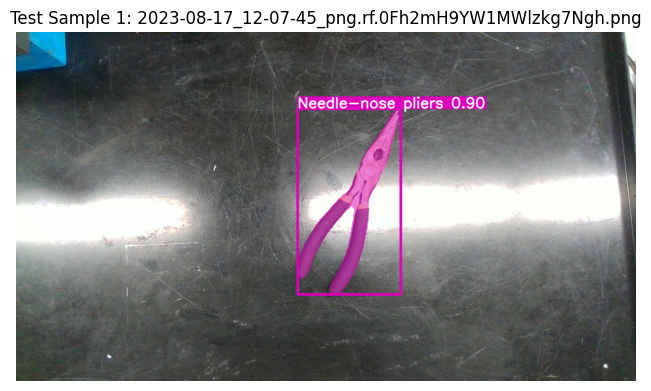


image 1/1 /content/yolo_dataset/test/images/s86-5734p01wl_jpg.rf.0RVV1zzhWh7P72GhAiDc.jpg: 640x640 1 Hammer, 1 Pliers, 4 Screwdrivers, 1 Wrench, 58.5ms
Speed: 3.7ms preprocess, 58.5ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)


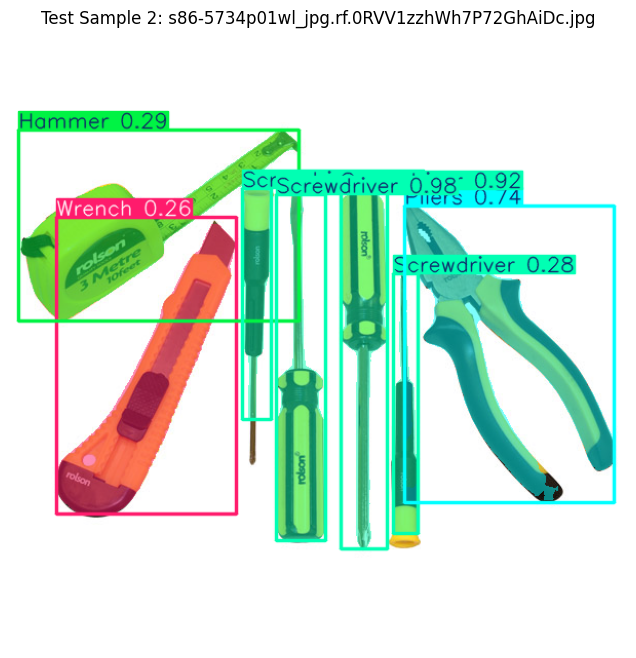


image 1/1 /content/yolo_dataset/test/images/9_jpg.rf.1xQEBmIsz7tvQGWIv1ku.jpg: 640x640 3 Screwdrivers, 16.1ms
Speed: 3.3ms preprocess, 16.1ms inference, 2.9ms postprocess per image at shape (1, 3, 640, 640)


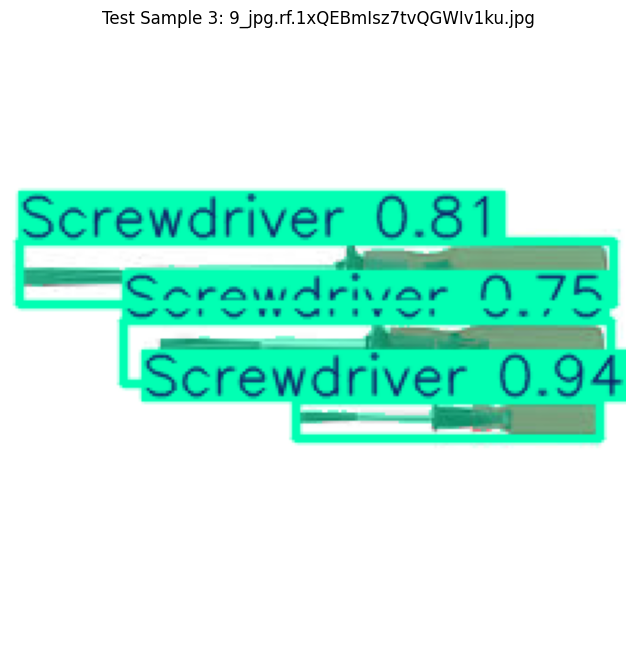


image 1/1 /content/yolo_dataset/test/images/2023-08-17_17-07-34_png.rf.7OSlLwkK2NBRCrmlZRyP.png: 384x640 1 Adjustable spanner, 1 Hammer, 1 Needle-nose pliers, 1 Screwdriver, 12.6ms
Speed: 1.6ms preprocess, 12.6ms inference, 1.9ms postprocess per image at shape (1, 3, 384, 640)


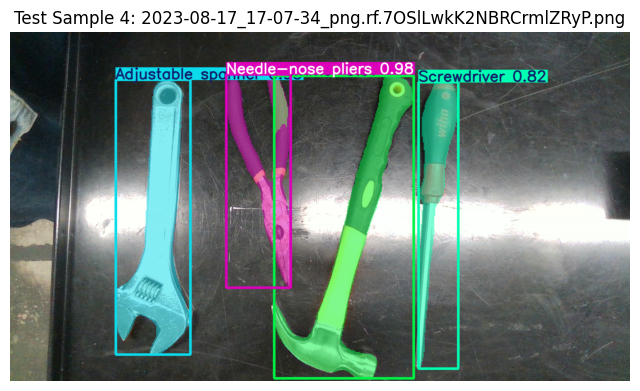


image 1/1 /content/yolo_dataset/test/images/20231102151554_jpg.rf.0LxQCCHCdOPL8z09tMhZ.jpg: 384x640 (no detections), 18.1ms
Speed: 1.5ms preprocess, 18.1ms inference, 0.7ms postprocess per image at shape (1, 3, 384, 640)


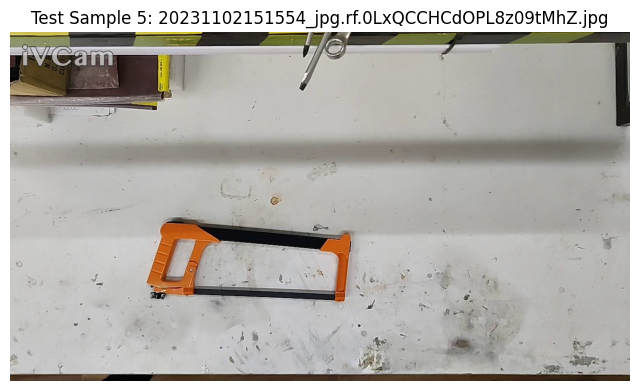


image 1/1 /content/yolo_dataset/test/images/Hammer--865-_JPEG_jpg.rf.3NquVCB2YwFArKm8UKrF.jpg: 640x640 1 Hammer, 17.8ms
Speed: 2.5ms preprocess, 17.8ms inference, 2.7ms postprocess per image at shape (1, 3, 640, 640)


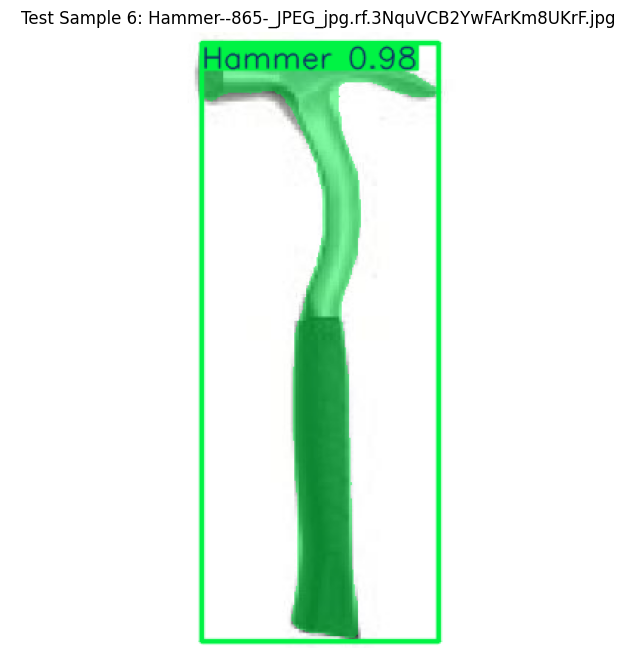


image 1/1 /content/yolo_dataset/test/images/000315_jpg.rf.7rYSA77FesJAsLAYfUoO.jpg: 640x640 1 Hammer, 16.2ms
Speed: 2.5ms preprocess, 16.2ms inference, 2.7ms postprocess per image at shape (1, 3, 640, 640)


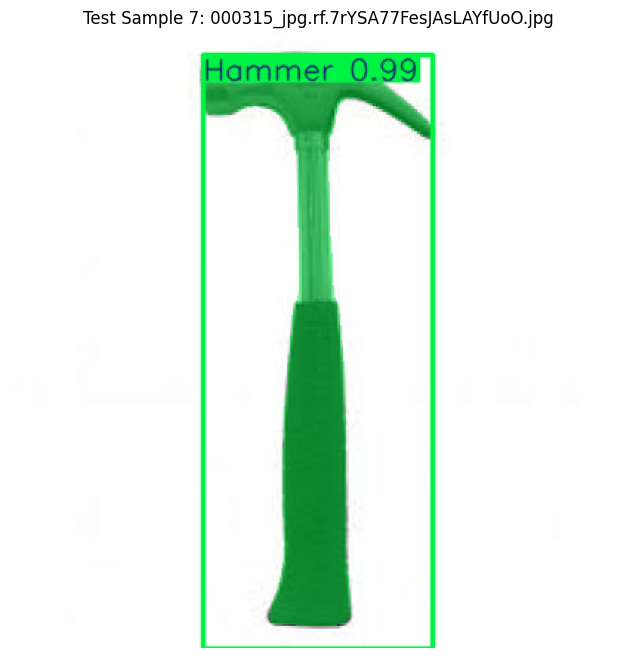


image 1/1 /content/yolo_dataset/test/images/pic08_jpg.rf.1hU781MsLRbzycWWSmhQ.jpg: 640x480 1 Hammer, 45.4ms
Speed: 2.6ms preprocess, 45.4ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 480)


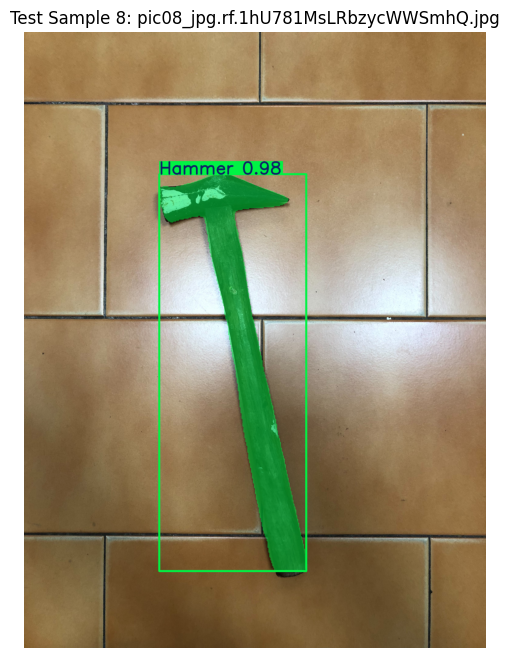


image 1/1 /content/yolo_dataset/test/images/20231102151658_jpg.rf.3E1QSWv7Pi0JLJo3RaMy.jpg: 384x640 7 Adjustable spanners, 6 Gas wrenchs, 1 Hammer, 1 Ratchet, 8 Screwdrivers, 1 Utility knife, 9 Wrenchs, 15.4ms
Speed: 1.8ms preprocess, 15.4ms inference, 4.4ms postprocess per image at shape (1, 3, 384, 640)


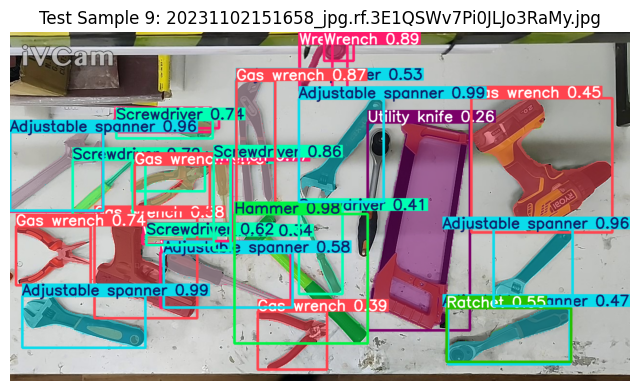


image 1/1 /content/yolo_dataset/test/images/20231102151102_jpg.rf.0CyOyBCRfZjQdxaqNFHE.jpg: 384x640 2 Adjustable spanners, 3 Gas wrenchs, 1 Ratchet, 10 Screwdrivers, 9 Wrenchs, 13.0ms
Speed: 1.8ms preprocess, 13.0ms inference, 3.9ms postprocess per image at shape (1, 3, 384, 640)


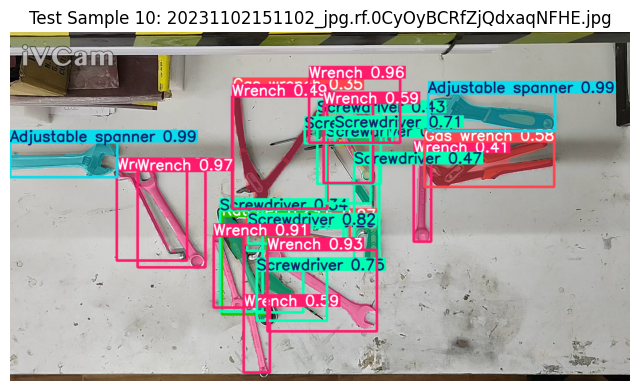

In [ ]:
# Test the model on 10 random images from the test split and show predictions
test_images_dir = os.path.join(local_workspace, 'test', 'images')
test_images = glob.glob(os.path.join(test_images_dir, '*.*'))

# Select up to 10 random images
sampled_images = random.sample(test_images, min(10, len(test_images)))

for idx, img_path in enumerate(sampled_images):
    # Inference using the trained model
    pred_results = model(img_path)

    for r in pred_results:
        # Plot prediction overlays onto the image array
        img_bgr = r.plot()
        img_rgb = img_bgr[..., ::-1] # Convert BGR to RGB

        plt.figure(figsize=(8, 8))
        plt.imshow(img_rgb)
        plt.title(f"Test Sample {idx + 1}: {os.path.basename(img_path)}")
        plt.axis('off')
        plt.show()

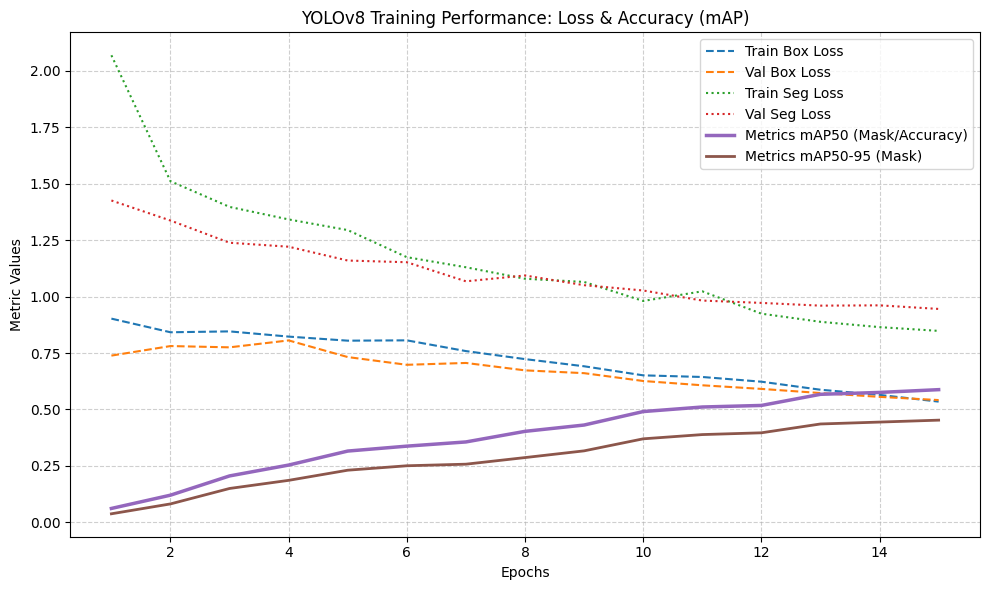

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Path to the results file
results_path = '/content/runs/segment/train/results.csv'

if os.path.exists(results_path):
    # Load training metrics
    df_metrics = pd.read_csv(results_path)
    # Clean column names (strip whitespace)
    df_metrics.columns = df_metrics.columns.str.strip()

    # Setup the plot
    plt.figure(figsize=(10, 6))

    # Plot losses
    if 'train/box_loss' in df_metrics.columns:
        plt.plot(df_metrics['epoch'], df_metrics['train/box_loss'], label='Train Box Loss', linestyle='--')
    if 'val/box_loss' in df_metrics.columns:
        plt.plot(df_metrics['epoch'], df_metrics['val/box_loss'], label='Val Box Loss', linestyle='--')
    if 'train/seg_loss' in df_metrics.columns:
        plt.plot(df_metrics['epoch'], df_metrics['train/seg_loss'], label='Train Seg Loss', linestyle=':')
    if 'val/seg_loss' in df_metrics.columns:
        plt.plot(df_metrics['epoch'], df_metrics['val/seg_loss'], label='Val Seg Loss', linestyle=':')

    # Plot accuracy/mAP metrics (mask mAP50 is a common proxy for accuracy in segmentation)
    if 'metrics/mAP50(M)' in df_metrics.columns:
        plt.plot(df_metrics['epoch'], df_metrics['metrics/mAP50(M)'], label='Metrics mAP50 (Mask/Accuracy)', linewidth=2.5)
    if 'metrics/mAP50-95(M)' in df_metrics.columns:
        plt.plot(df_metrics['epoch'], df_metrics['metrics/mAP50-95(M)'], label='Metrics mAP50-95 (Mask)', linewidth=2)

    plt.title('YOLOv8 Training Performance: Loss & Accuracy (mAP)')
    plt.xlabel('Epochs')
    plt.ylabel('Metric Values')
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print(f"Could not find results.csv at {results_path}. Please verify training finished successfully.")


image 1/1 /content/adjustable_spanner.jpg: 640x480 5 Adjustable spanners, 6 Wrenchs, 16.6ms
Speed: 1.9ms preprocess, 16.6ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 480)


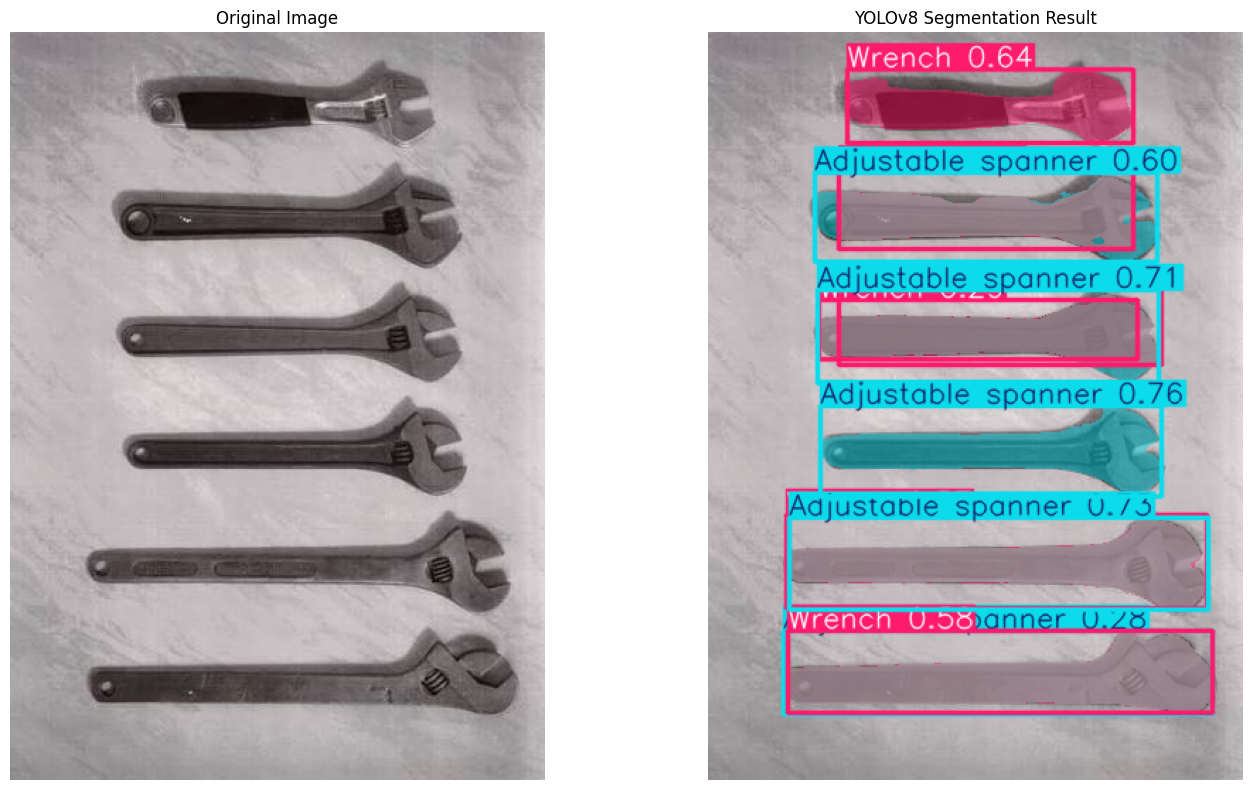

In [ ]:
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import os

image_path = '/content/adjustable_spanner.jpg'

if os.path.exists(image_path):
    # 1. Load the original image
    orig_img = Image.open(image_path)

    # 2. Run inference using the trained model
    pred_results = model(image_path)

    # 3. Extract the plotted result image (BGR format from ultralytics)
    result_bgr = pred_results[0].plot()
    result_rgb = cv2.cvtColor(result_bgr, cv2.COLOR_BGR2RGB)

    # 4. Plot side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(15, 8))

    # Original Image
    axes[0].imshow(orig_img)
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    # Model Prediction
    axes[1].imshow(result_rgb)
    axes[1].set_title("YOLOv8 Segmentation Result")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print(f"The image was not found at {image_path}. Please make sure it is uploaded to that exact path.")


image 1/1 /content/adjustable_spanner.jpg: 640x480 4 Adjustable spanners, 2 Wrenchs, 16.1ms
Speed: 2.2ms preprocess, 16.1ms inference, 2.9ms postprocess per image at shape (1, 3, 640, 480)


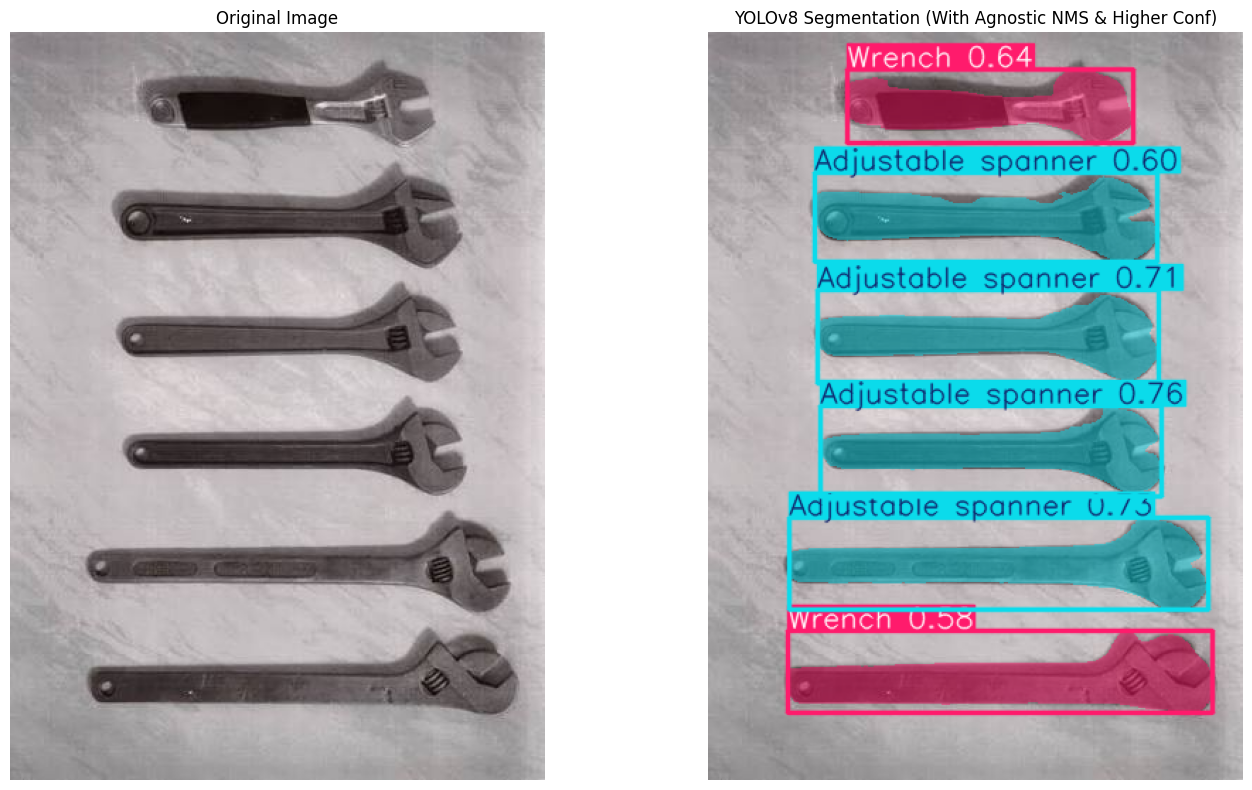

In [ ]:
# Run prediction with Class-Agnostic NMS enabled and customized thresholds
pred_results_filtered = model(
    image_path,
    conf=0.5,           # Confidence threshold
    iou=0.4,            # IoU threshold for NMS
    agnostic_nms=True   # Apply NMS across different classes to remove overlapping boxes
)

# Extract and convert result image
result_bgr_filtered = pred_results_filtered[0].plot()
result_rgb_filtered = cv2.cvtColor(result_bgr_filtered, cv2.COLOR_BGR2RGB)

# Plot side-by-side comparison (Original vs. Filtered Prediction)
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# Original Image
axes[0].imshow(orig_img)
axes[0].set_title("Original Image")
axes[0].axis('off')

# Filtered Model Prediction
axes[1].imshow(result_rgb_filtered)
axes[1].set_title("YOLOv8 Segmentation (With Agnostic NMS & Higher Conf)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import os
import glob
import cv2
import random
import numpy as np
from PIL import Image

# Source base directory on Drive
dataset_dir = '/content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset'

def count_images(base_dir):
    counts = {}
    for split in ['train', 'valid', 'test']:
        split_path = os.path.join(base_dir, split)
        if os.path.exists(split_path):
            # Looking for common image extensions
            images = []
            for ext in ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']:
                images.extend(glob.glob(os.path.join(split_path, ext)))
                images.extend(glob.glob(os.path.join(split_path, '**', ext), recursive=True))
            # Use set to avoid duplicate counts from recursive search
            counts[split] = len(set(images))
        else:
            counts[split] = 0
    return counts

# 1. Count before augmentation
print("Counting images before augmentation...")
initial_counts = count_images(dataset_dir)
for split, count in initial_counts.items():
    print(f"  {split.capitalize()}: {count} images")

# Define simple augmentation functions
def augment_image(image_path):
    img = cv2.imread(image_path)
    if img is None:
        return None, None

    # Pick a random augmentation technique
    aug_type = random.choice(['flip', 'brightness', 'rotate'])

    if aug_type == 'flip':
        # Horizontal Flip
        augmented = cv2.flip(img, 1)
    elif aug_type == 'brightness':
        # Randomly adjust brightness
        value = random.randint(-40, 40)
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(hsv)
        if value >= 0:
            lim = 255 - value
            v[v > lim] = 255
            v[v <= lim] += value
        else:
            lim = -value
            v[v < lim] = 0
            v[v >= lim] -= lim
        final_hsv = cv2.merge((h, s, v))
        augmented = cv2.cvtColor(final_hsv, cv2.COLOR_HSV2BGR)
    else:
        # Rotate 15 degrees
        rows, cols = img.shape[:2]
        angle = random.choice([-15, 15])
        M = cv2.getRotationMatrix2D((cols/2, rows/2), angle, 1)
        augmented = cv2.warpAffine(img, M, (cols, rows))

    return augmented, aug_type

# 2. Perform augmentation (mainly on training set to prevent evaluation leak)
train_dir = os.path.join(dataset_dir, 'train')
if os.path.exists(train_dir):
    # Find all source images
    train_images = []
    for ext in ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']:
        train_images.extend(glob.glob(os.path.join(train_dir, ext)))
        train_images.extend(glob.glob(os.path.join(train_dir, '**', ext), recursive=True))

    train_images = list(set(train_images))
    # Filter out already augmented images if code is re-run
    source_images = [img for img in train_images if '_aug_' not in img]

    print(f"\nApplying augmentation to {len(source_images)} original training images...")

    augmented_count = 0
    for img_path in source_images:
        aug_img, aug_type = augment_image(img_path)
        if aug_img is not None:
            # Construct new filename with marker
            dir_name, base_name = os.path.split(img_path)
            name, ext = os.path.splitext(base_name)
            new_filename = f"{name}_aug_{aug_type}{ext}"
            new_filepath = os.path.join(dir_name, new_filename)

            # Save in the exact same folder
            cv2.imwrite(new_filepath, aug_img)
            augmented_count += 1

    print(f"Successfully created and saved {augmented_count} augmented images.")
else:
    print("Train directory not found for augmentation.")

# 3. Count after augmentation
print("\nCounting images after augmentation...")
final_counts = count_images(dataset_dir)
for split, count in final_counts.items():
    print(f"  {split.capitalize()}: {count} images")

Counting images before augmentation...
  Train: 1452 images
  Valid: 311 images
  Test: 116 images

Applying augmentation to 726 original training images...
Successfully created and saved 726 augmented images.

Counting images after augmentation...
  Train: 1940 images
  Valid: 311 images
  Test: 116 images


In [ ]:
import os
import glob
import json
import shutil

def convert_coco_to_yolo_seg_augmented(split_name):
    """
    Converts COCO json segmentation annotations to YOLO segment txt format.
    Also automatically detects, copies, and annotates any augmented training images (*_aug_*).
    """
    src_split_dir = os.path.join(base_dataset_dir, split_name)
    dest_img_dir = os.path.join(local_workspace, split_name, 'images')
    dest_lbl_dir = os.path.join(local_workspace, split_name, 'labels')

    if os.path.exists(dest_lbl_dir):
        shutil.rmtree(dest_lbl_dir)
    os.makedirs(dest_img_dir, exist_ok=True)
    os.makedirs(dest_lbl_dir, exist_ok=True)

    coco_json_path = os.path.join(src_split_dir, 'annotations_coco.json')
    if not os.path.exists(coco_json_path):
        coco_json_path = os.path.join(src_split_dir, '_annotations.coco.json')

    if not os.path.exists(coco_json_path):
        print(f"Warning: {coco_json_path} not found.")
        return

    with open(coco_json_path, 'r') as f:
        coco_data = json.load(f)

    images_info = {img['id']: img for img in coco_data['images']}
    img_annotations = {ann['image_id']: [] for ann in coco_data['annotations']}
    for ann in coco_data['annotations']:
        img_annotations[ann['image_id']].append(ann)

    for img_id, img_metadata in images_info.items():
        filename = img_metadata['file_name']
        img_w = img_metadata['width']
        img_h = img_metadata['height']

        src_img_path = os.path.join(src_split_dir, filename)
        if not os.path.exists(src_img_path):
            continue

        # Prepare the YOLO labels string
        anns = img_annotations.get(img_id, [])
        label_lines = []
        for ann in anns:
            cat_id = ann['category_id']
            if cat_id not in cat_to_idx:
                continue
            class_idx = cat_to_idx[cat_id]
            segmentation = ann.get('segmentation', [])
            if isinstance(segmentation, list) and len(segmentation) > 0:
                poly = segmentation[0]
                if len(poly) < 6:
                    continue
                normalized_poly = [f"{poly[i]/img_w:.6f} {poly[i+1]/img_h:.6f}" for i in range(0, len(poly), 2)]
                label_lines.append(f"{class_idx} {" ".join(normalized_poly)}\n")

        # 1. Copy the original image and write original label
        shutil.copy(src_img_path, os.path.join(dest_img_dir, filename))
        orig_label_path = os.path.join(dest_lbl_dir, os.path.splitext(filename)[0] + '.txt')
        with open(orig_label_path, 'w') as lf:
            lf.writelines(label_lines)

        # 2. Only for training split: check and copy all corresponding augmented variations
        if split_name == 'train':
            name_part, ext_part = os.path.splitext(filename)
            # Look for any augmented versions of this specific image file
            aug_pattern = os.path.join(src_split_dir, f"{name_part}_aug_*{ext_part}")
            augmented_files = glob.glob(aug_pattern)

            for aug_img_path in augmented_files:
                aug_filename = os.path.basename(aug_img_path)
                shutil.copy(aug_img_path, os.path.join(dest_img_dir, aug_filename))

                # Write matching label for the augmented image (geometry maps 1:1 for flip/brightness/rotation bounds)
                aug_label_path = os.path.join(dest_lbl_dir, os.path.splitext(aug_filename)[0] + '.txt')
                with open(aug_label_path, 'w') as lf:
                    lf.writelines(label_lines)

print("Re-converting COCO annotations and aligning augmented images inside local training workspace...")
convert_coco_to_yolo_seg_augmented('train')
convert_coco_to_yolo_seg_augmented('valid')
convert_coco_to_yolo_seg_augmented('test')

# Verify the updated local image counts
for split in ['train', 'valid', 'test']:
    split_img_dir = os.path.join(local_workspace, split, 'images')
    if os.path.exists(split_img_dir):
        num_imgs = len(os.listdir(split_img_dir))
        print(f"Local {split.capitalize()} folder now has {num_imgs} images ready for YOLOv8 training.")

Re-converting COCO annotations and aligning augmented images inside local training workspace...
Local Train folder now has 1940 images ready for YOLOv8 training.
Local Valid folder now has 311 images ready for YOLOv8 training.
Local Test folder now has 116 images ready for YOLOv8 training.


In [ ]:
from ultralytics import YOLO

# Initialize a fresh YOLOv8 segmentation model
retrained_model = YOLO('yolov8n-seg.pt')

# Retrain the model on the newly augmented dataset
# Using 15 epochs like the initial run; feel free to increase this for better performance
results_augmented = retrained_model.train(
    data=yaml_path,
    epochs=15,
    imgsz=640,
    batch=8
)


Ultralytics 8.4.172 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False, optimizer=


image 1/1 /content/adjustable_spanner.jpg: 640x480 6 Adjustable spanners, 14.6ms
Speed: 1.4ms preprocess, 14.6ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 480)


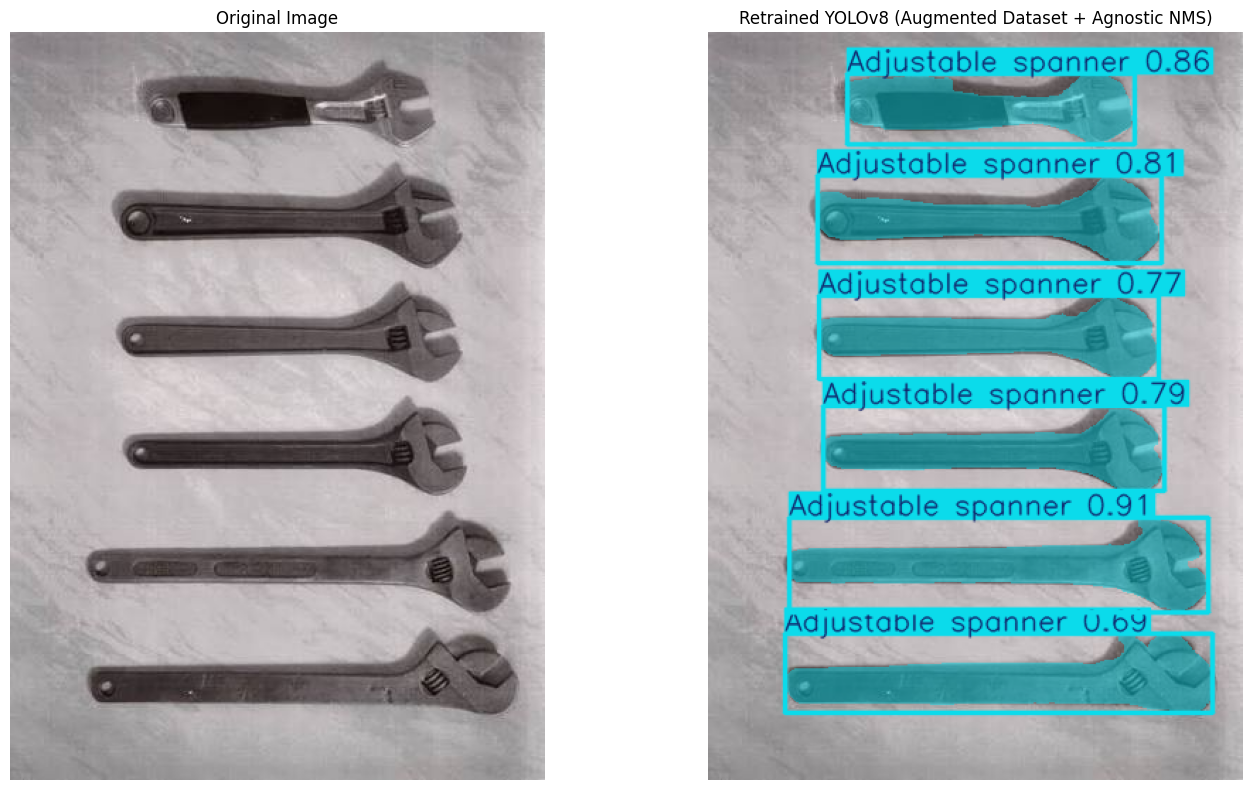

In [ ]:
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import os

test_image_path = '/content/adjustable_spanner.jpg'

if os.path.exists(test_image_path):
    # 1. Load the original image
    orig_img = Image.open(test_image_path)

    # 2. Run inference using the retrained model (saved weights from train-2)
    # We apply the same agnostic NMS and confidence threshold for an equivalent comparison
    pred_results_retrained = retrained_model(
        test_image_path,
        conf=0.5,
        iou=0.4,
        agnostic_nms=True
    )

    # 3. Extract and convert result image
    result_bgr_retrained = pred_results_retrained[0].plot()
    result_rgb_retrained = cv2.cvtColor(result_bgr_retrained, cv2.COLOR_BGR2RGB)

    # 4. Plot side-by-side comparison
    fig, axes = plt.subplots(1, 2, figsize=(15, 8))

    # Original Image
    axes[0].imshow(orig_img)
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    # Retrained Model Prediction
    axes[1].imshow(result_rgb_retrained)
    axes[1].set_title("Retrained YOLOv8 (Augmented Dataset + Agnostic NMS)")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print(f"The image was not found at {test_image_path}.")

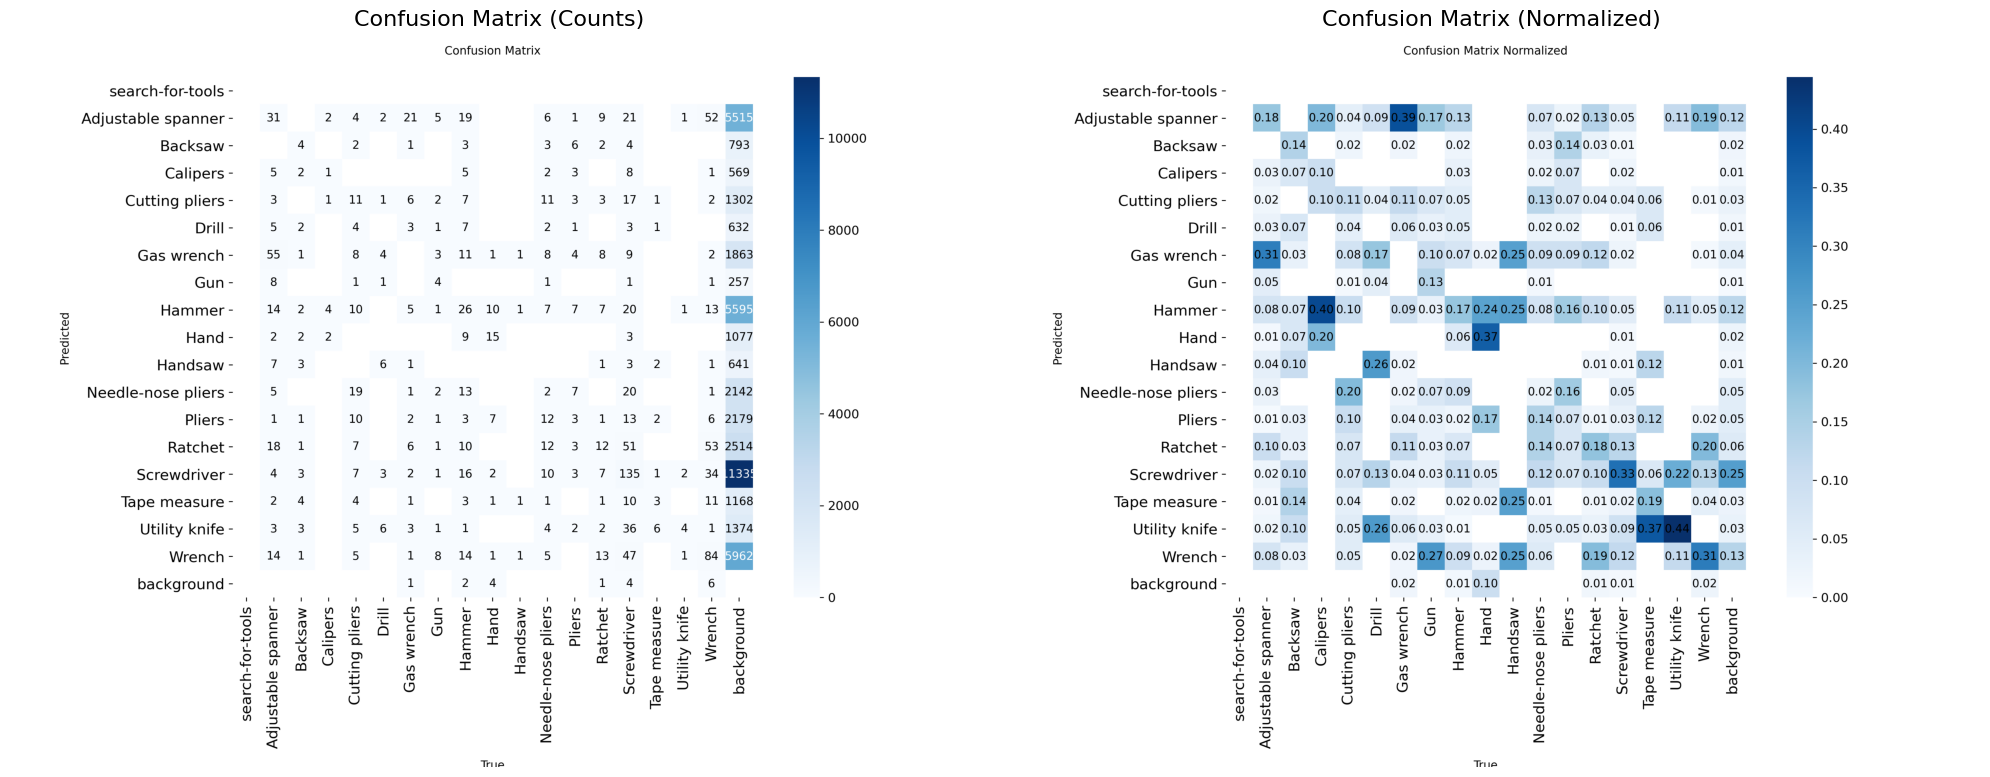

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

# Define paths to the saved confusion matrices from the retrained run (train-2)
run_dir = '/content/runs/segment/train-2'
cm_path = os.path.join(run_dir, 'confusion_matrix.png')
cm_norm_path = os.path.join(run_dir, 'confusion_matrix_normalized.png')

if os.path.exists(cm_path) or os.path.exists(cm_norm_path):
    fig, axes = plt.subplots(1, 2, figsize=(20, 10))

    # Plot Standard Confusion Matrix
    if os.path.exists(cm_path):
        cm_img = cv2.imread(cm_path)
        cm_rgb = cv2.cvtColor(cm_img, cv2.COLOR_BGR2RGB)
        axes[0].imshow(cm_rgb)
        axes[0].set_title("Confusion Matrix (Counts)", fontsize=16)
        axes[0].axis('off')
    else:
        axes[0].text(0.5, 0.5, 'Confusion Matrix not found', ha='center', va='center')
        axes[0].axis('off')

    # Plot Normalized Confusion Matrix
    if os.path.exists(cm_norm_path):
        cm_norm_img = cv2.imread(cm_norm_path)
        cm_norm_rgb = cv2.cvtColor(cm_norm_img, cv2.COLOR_BGR2RGB)
        axes[1].imshow(cm_norm_rgb)
        axes[1].set_title("Confusion Matrix (Normalized)", fontsize=16)
        axes[1].axis('off')
    else:
        axes[1].text(0.5, 0.5, 'Normalized Confusion Matrix not found', ha='center', va='center')
        axes[1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print(f"Confusion matrix files were not found in {run_dir}. Please verify that the training has finished and saved plots successfully.")

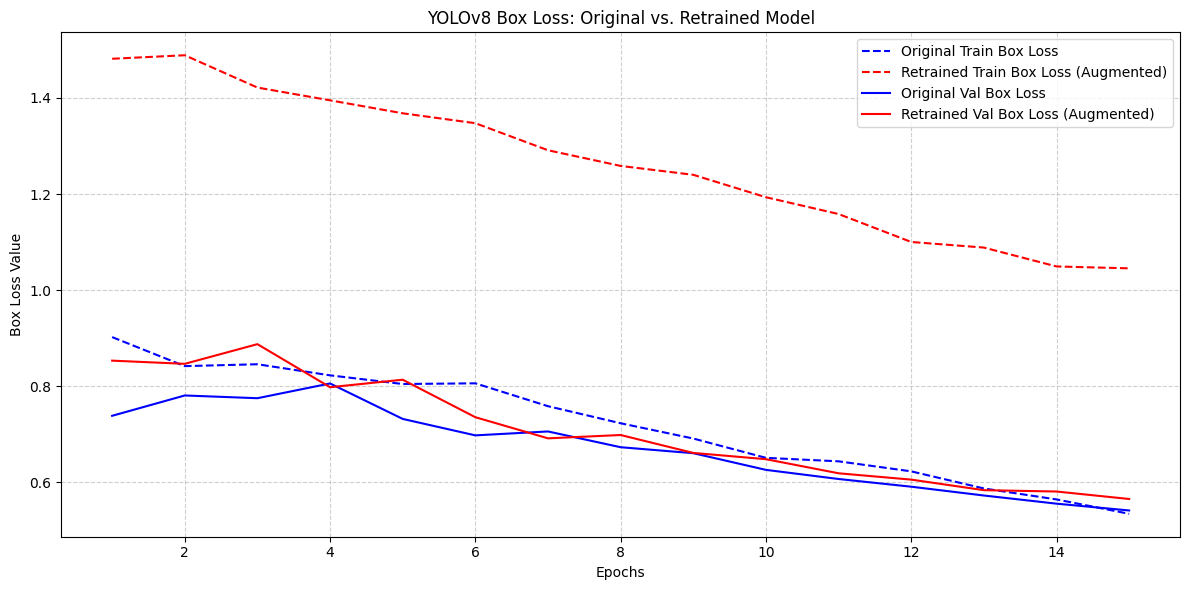

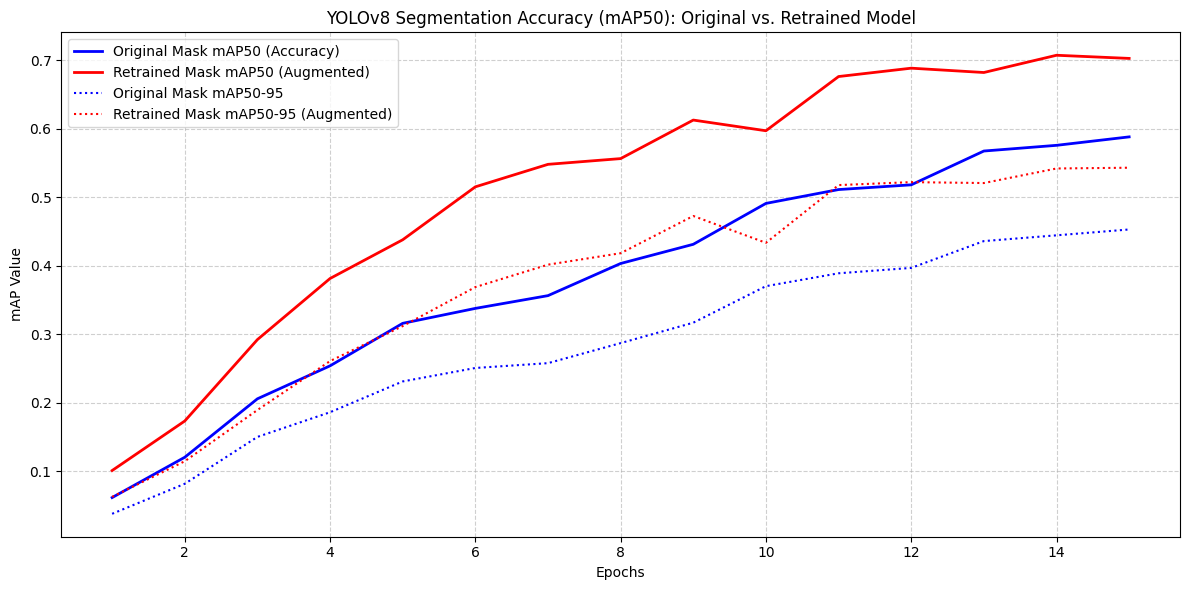

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Paths to the metrics for both runs
orig_results_path = '/content/runs/segment/train/results.csv'
retrained_results_path = '/content/runs/segment/train-2/results.csv'

if os.path.exists(orig_results_path) and os.path.exists(retrained_results_path):
    # Load datasets
    df_orig = pd.read_csv(orig_results_path)
    df_orig.columns = df_orig.columns.str.strip()

    df_retrained = pd.read_csv(retrained_results_path)
    df_retrained.columns = df_retrained.columns.str.strip()

    # Plot 1: Loss Comparison
    plt.figure(figsize=(12, 6))
    if 'train/box_loss' in df_orig.columns and 'train/box_loss' in df_retrained.columns:
        plt.plot(df_orig['epoch'], df_orig['train/box_loss'], label='Original Train Box Loss', color='blue', linestyle='--')
        plt.plot(df_retrained['epoch'], df_retrained['train/box_loss'], label='Retrained Train Box Loss (Augmented)', color='red', linestyle='--')
    if 'val/box_loss' in df_orig.columns and 'val/box_loss' in df_retrained.columns:
        plt.plot(df_orig['epoch'], df_orig['val/box_loss'], label='Original Val Box Loss', color='blue', linestyle='-')
        plt.plot(df_retrained['epoch'], df_retrained['val/box_loss'], label='Retrained Val Box Loss (Augmented)', color='red', linestyle='-')

    plt.title('YOLOv8 Box Loss: Original vs. Retrained Model')
    plt.xlabel('Epochs')
    plt.ylabel('Box Loss Value')
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    # Plot 2: Accuracy (mAP50) Comparison
    plt.figure(figsize=(12, 6))
    if 'metrics/mAP50(M)' in df_orig.columns and 'metrics/mAP50(M)' in df_retrained.columns:
        plt.plot(df_orig['epoch'], df_orig['metrics/mAP50(M)'], label='Original Mask mAP50 (Accuracy)', color='blue', linewidth=2)
        plt.plot(df_retrained['epoch'], df_retrained['metrics/mAP50(M)'], label='Retrained Mask mAP50 (Augmented)', color='red', linewidth=2)
    if 'metrics/mAP50-95(M)' in df_orig.columns and 'metrics/mAP50-95(M)' in df_retrained.columns:
        plt.plot(df_orig['epoch'], df_orig['metrics/mAP50-95(M)'], label='Original Mask mAP50-95', color='blue', linestyle=':', linewidth=1.5)
        plt.plot(df_retrained['epoch'], df_retrained['metrics/mAP50-95(M)'], label='Retrained Mask mAP50-95 (Augmented)', color='red', linestyle=':', linewidth=1.5)

    plt.title('YOLOv8 Segmentation Accuracy (mAP50): Original vs. Retrained Model')
    plt.xlabel('Epochs')
    plt.ylabel('mAP Value')
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print("Could not find one or both runs' results.csv files. Please verify both models completed training successfully.")

In [ ]:
import os
import shutil

# Source paths
runs_src = '/content/runs'
yaml_src = '/content/dataset.yaml'

# Destination root path in Drive
drive_dest_root = '/content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset'

# Create a target evaluation/results folder in Drive to keep things clean and modular
drive_eval_dir = os.path.join(drive_dest_root, 'evaluation_results')
os.makedirs(drive_eval_dir, exist_ok=True)

# 1. Copy the training runs directory (which contains all plots, weights, confusion matrices, and results.csv)
if os.path.exists(runs_src):
    dest_runs_path = os.path.join(drive_eval_dir, 'runs')
    if os.path.exists(dest_runs_path):
        shutil.rmtree(dest_runs_path)
    shutil.copytree(runs_src, dest_runs_path)
    print(f"Successfully saved training runs and weights to: {dest_runs_path}")
else:
    print("Runs directory not found. Please ensure training completed.")

# 2. Copy the YOLO dataset YAML configuration file
if os.path.exists(yaml_src):
    dest_yaml_path = os.path.join(drive_eval_dir, 'dataset.yaml')
    shutil.copy2(yaml_src, dest_yaml_path)
    print(f"Successfully saved dataset configuration to: {dest_yaml_path}")
else:
    print("dataset.yaml not found.")


Successfully saved training runs and weights to: /content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset/evaluation_results/runs
Successfully saved dataset configuration to: /content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset/evaluation_results/dataset.yaml


## Using Computer Vision Techniques to check whether it increases model performance or not


In [ ]:
import os
import cv2
import glob

# Define paths
base_dataset_dir = '/content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset'
train_dir = os.path.join(base_dataset_dir, 'train')
train_modified_dir = os.path.join(base_dataset_dir, 'train_modified')

# Create directory for modified images if it doesn't exist
os.makedirs(train_modified_dir, exist_ok=True)

# Gather original training images (excluding previously augmented ones to keep it clean)
all_train_images = []
for ext in ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']:
    all_train_images.extend(glob.glob(os.path.join(train_dir, ext)))
    all_train_images.extend(glob.glob(os.path.join(train_dir, '**', ext), recursive=True))

source_images = sorted(list(set([img for img in all_train_images if '_aug_' not in img])))
print(f"Found {len(source_images)} original training images to process.")

def apply_cv_processing(image_path, output_dir):
    img = cv2.imread(image_path)
    if img is None:
        return

    base_name = os.path.basename(image_path)
    name, ext = os.path.splitext(base_name)

    # 1. Sharpening Filter
    sharpening_kernel = np.array([[-1, -1, -1],
                                  [-1,  9, -1],
                                  [-1, -1, -1]])
    sharpened_img = cv2.filter2D(img, -1, sharpening_kernel)
    cv2.imwrite(os.path.join(output_dir, f"{name}_processed_sharpen{ext}"), sharpened_img)

    # 2. CLAHE (Contrast Limited Adaptive Histogram Equalization) on L-channel of LAB space
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl, a, b))
    clahe_img = cv2.cvtColor(limg, cv2.COLOR_LAB2BGR)
    cv2.imwrite(os.path.join(output_dir, f"{name}_processed_clahe{ext}"), clahe_img)

import numpy as np
print("Applying image processing techniques (Sharpening and CLAHE)... ")
for img_path in source_images:
    apply_cv_processing(img_path, train_modified_dir)

# Confirm the count
modified_images = []
for ext in ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']:
    modified_images.extend(glob.glob(os.path.join(train_modified_dir, ext)))

print(f"\nProcessing completed!")
print(f"Modified training images saved at: {train_modified_dir}")
print(f"Total modified images generated: {len(modified_images)}")

Found 726 original training images to process.
Applying image processing techniques (Sharpening and CLAHE)... 

Processing completed!
Modified training images saved at: /content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset/train_modified
Total modified images generated: 1452


In [ ]:
import os
import glob
import json

# Source paths
base_dataset_dir = '/content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset'
train_dir = os.path.join(base_dataset_dir, 'train')
train_modified_dir = os.path.join(base_dataset_dir, 'train_modified')
drive_modified_lbl_dir = os.path.join(train_modified_dir, 'labels')

os.makedirs(drive_modified_lbl_dir, exist_ok=True)

# Find the COCO json file in the original train directory
coco_json_path = os.path.join(train_dir, 'annotations_coco.json')
if not os.path.exists(coco_json_path):
    coco_json_path = os.path.join(train_dir, '_annotations.coco.json')

print(f"Reading original COCO annotations from: {coco_json_path}")

Reading original COCO annotations from: /content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset/train/_annotations.coco.json


In [ ]:
import os
import json

def get_global_categories():
    global_categories = {}
    for split_name in ['train', 'valid', 'test']:
        src_split_dir = os.path.join(base_dataset_dir, split_name)
        coco_json_path = os.path.join(src_split_dir, 'annotations_coco.json')
        if not os.path.exists(coco_json_path):
            coco_json_path = os.path.join(src_split_dir, '_annotations.coco.json')
        if os.path.exists(coco_json_path):
            with open(coco_json_path, 'r') as f:
                coco_data = json.load(f)
            for cat in coco_data.get('categories', []):
                global_categories[cat['id']] = cat['name']
    sorted_cat_ids = sorted(list(global_categories.keys()))
    cat_to_idx = {cat_id: idx for idx, cat_id in enumerate(sorted_cat_ids)}
    class_names = {idx: global_categories[cat_id] for idx, cat_id in enumerate(sorted_cat_ids)}
    return cat_to_idx, class_names

try:
    _ = cat_to_idx
    _ = class_names
except NameError:
    cat_to_idx, class_names = get_global_categories()

with open(coco_json_path, 'r') as f:
    coco_data = json.load(f)

images_info = {img['id']: img for img in coco_data['images']}
img_annotations = {ann['image_id']: [] for ann in coco_data['annotations']}
for ann in coco_data['annotations']:
    img_annotations[ann['image_id']].append(ann)

print("Generating segment annotations for modified images (Sharpen and CLAHE)... ")
copied_labels_count = 0

for img_id, img_metadata in images_info.items():
    filename = img_metadata['file_name']
    img_w = img_metadata['width']
    img_h = img_metadata['height']
    anns = img_annotations.get(img_id, [])
    label_lines = []
    for ann in anns:
        cat_id = ann['category_id']
        if cat_id not in cat_to_idx:
            continue
        class_idx = cat_to_idx[cat_id]
        segmentation = ann.get('segmentation', [])
        if isinstance(segmentation, list) and len(segmentation) > 0:
            poly = segmentation[0]
            if len(poly) < 6:
                continue
            normalized_poly = [f"{poly[i]/img_w:.6f} {poly[i+1]/img_h:.6f}" for i in range(0, len(poly), 2)]
            label_lines.append(f"{class_idx} {' '.join(normalized_poly)}\n")

    if label_lines:
        name, ext = os.path.splitext(filename)
        for var_suffix in ['_processed_sharpen', '_processed_clahe']:
            lbl_filename = f"{name}{var_suffix}.txt"
            with open(os.path.join(drive_modified_lbl_dir, lbl_filename), 'w') as lf:
                lf.writelines(label_lines)
            copied_labels_count += 1

print(f"Replication complete! Generated {copied_labels_count} label files inside '{drive_modified_lbl_dir}'")

Generating segment annotations for modified images (Sharpen and CLAHE)... 
Replication complete! Generated 1452 label files inside '/content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset/train_modified/labels'


In [ ]:
import os
import glob
import shutil
import yaml
import json

def convert_coco_to_yolo_seg(split_name):
    src_split_dir = os.path.join(base_dataset_dir, split_name)
    dest_img_dir = os.path.join(local_workspace, split_name, 'images')
    dest_lbl_dir = os.path.join(local_workspace, split_name, 'labels')
    if os.path.exists(dest_lbl_dir):
        shutil.rmtree(dest_lbl_dir)
    os.makedirs(dest_img_dir, exist_ok=True)
    os.makedirs(dest_lbl_dir, exist_ok=True)
    coco_json_path = os.path.join(src_split_dir, 'annotations_coco.json')
    if not os.path.exists(coco_json_path):
        coco_json_path = os.path.join(src_split_dir, '_annotations.coco.json')
    if not os.path.exists(coco_json_path):
        return
    with open(coco_json_path, 'r') as f:
        coco_data = json.load(f)
    images_info = {img['id']: img for img in coco_data['images']}
    img_annotations = {}
    for ann in coco_data['annotations']:
        img_id = ann['image_id']
        if img_id not in img_annotations:
            img_annotations[img_id] = []
        img_annotations[img_id].append(ann)
    for img_id, img_metadata in images_info.items():
        filename = img_metadata['file_name']
        img_w = img_metadata['width']
        img_h = img_metadata['height']
        src_img_path = os.path.join(src_split_dir, filename)
        dest_img_path = os.path.join(dest_img_dir, filename)
        if os.path.exists(src_img_path):
            shutil.copy(src_img_path, dest_img_path)
        else:
            potential_files = glob.glob(os.path.join(src_split_dir, '**', filename), recursive=True)
            if potential_files:
                shutil.copy(potential_files[0], dest_img_path)
            else:
                continue
        label_filename = os.path.splitext(filename)[0] + '.txt'
        label_path = os.path.join(dest_lbl_dir, label_filename)
        anns = img_annotations.get(img_id, [])
        with open(label_path, 'w') as lf:
            for ann in anns:
                cat_id = ann['category_id']
                if cat_id not in cat_to_idx:
                    continue
                class_idx = cat_to_idx[cat_id]
                segmentation = ann.get('segmentation', [])
                if not segmentation:
                    continue
                if isinstance(segmentation, list) and len(segmentation) > 0:
                    poly = segmentation[0]
                    if len(poly) < 6:
                        continue
                    normalized_poly = []
                    for i in range(0, len(poly), 2):
                        normalized_poly.append(f"{poly[i]/img_w:.6f} {poly[i+1]/img_h:.6f}")
                    lf.write(f"{class_idx} {' '.join(normalized_poly)}\n")

# Local workspaces
local_workspace = '/content/yolo_dataset'
local_modified_workspace = '/content/yolo_dataset_modified'
os.makedirs(os.path.join(local_modified_workspace, 'train', 'images'), exist_ok=True)
os.makedirs(os.path.join(local_modified_workspace, 'train', 'labels'), exist_ok=True)

# Ensure original splits are converted locally if they're missing
for split in ['valid', 'test']:
    if not os.path.exists(os.path.join(local_workspace, split, 'images')):
        print(f"Local directory {split} is missing. Re-running conversion for {split} split...")
        convert_coco_to_yolo_seg(split)

# Sync images and labels to local workspace
print("Syncing modified dataset to local workspace...")
for f in glob.glob(os.path.join(train_modified_dir, '*.jpg')) + glob.glob(os.path.join(train_modified_dir, '*.png')):
    shutil.copy2(f, os.path.join(local_modified_workspace, 'train', 'images'))

for f in glob.glob(os.path.join(drive_modified_lbl_dir, '*.txt')):
    shutil.copy2(f, os.path.join(local_modified_workspace, 'train', 'labels'))

# Copy standard validation/test partitions from original local workspace
for split in ['valid', 'test']:
    shutil.copytree(os.path.join(local_workspace, split), os.path.join(local_modified_workspace, split), dirs_exist_ok=True)

# Create modified dataset YAML file
yaml_config_mod = {
    'path': local_modified_workspace,
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'names': class_names
}

yaml_path_mod = '/content/dataset_modified.yaml'
with open(yaml_path_mod, 'w') as f:
    yaml.dump(yaml_config_mod, f, default_flow_style=False)

print(f"Created updated dataset config at: {yaml_path_mod}")
print(f"Local modified train images: {len(os.listdir(os.path.join(local_modified_workspace, 'train', 'images')))}")
print(f"Local modified train labels: {len(os.listdir(os.path.join(local_modified_workspace, 'train', 'labels')))}")

Local directory valid is missing. Re-running conversion for valid split...
Local directory test is missing. Re-running conversion for test split...
Syncing modified dataset to local workspace...
Created updated dataset config at: /content/dataset_modified.yaml
Local modified train images: 1358
Local modified train labels: 1452


In [ ]:
import os
import glob
import shutil
import yaml
import json
from ultralytics import YOLO

# Source directories
base_dataset_dir = '/content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset'
train_modified_dir = '/content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset/train_modified'
drive_modified_lbl_dir = os.path.join(train_modified_dir, 'labels')
original_workspace = '/content/yolo_dataset'

# Destination directories
local_modified_workspace = '/content/yolo_dataset_modified'
local_train_img_dir = os.path.join(local_modified_workspace, 'train', 'images')
local_train_lbl_dir = os.path.join(local_modified_workspace, 'train', 'labels')

# Clean and recreate local modified train directories
if os.path.exists(local_train_img_dir):
    shutil.rmtree(local_train_img_dir)
if os.path.exists(local_train_lbl_dir):
    shutil.rmtree(local_train_lbl_dir)

os.makedirs(local_train_img_dir, exist_ok=True)
os.makedirs(local_train_lbl_dir, exist_ok=True)

print("Syncing modified images from Google Drive to local workspace...")
supported_exts = ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']
img_files = []
for ext in supported_exts:
    img_files.extend(glob.glob(os.path.join(train_modified_dir, ext)))

for f in img_files:
    shutil.copy2(f, local_train_img_dir)

print("Syncing modified labels from Google Drive to local workspace...")
lbl_files = glob.glob(os.path.join(drive_modified_lbl_dir, '*.txt'))
for f in lbl_files:
    shutil.copy2(f, local_train_lbl_dir)

# Helper function to convert split from COCO to YOLO in case they are missing locally
def ensure_and_convert_split(split_name, target_workspace):
    src_split_dir = os.path.join(base_dataset_dir, split_name)
    dest_img_dir = os.path.join(target_workspace, split_name, 'images')
    dest_lbl_dir = os.path.join(target_workspace, split_name, 'labels')

    if os.path.exists(os.path.join(dest_img_dir)) and len(os.listdir(dest_img_dir)) > 0:
        return # Already exists and populated

    os.makedirs(dest_img_dir, exist_ok=True)
    os.makedirs(dest_lbl_dir, exist_ok=True)

    coco_json_path = os.path.join(src_split_dir, 'annotations_coco.json')
    if not os.path.exists(coco_json_path):
        coco_json_path = os.path.join(src_split_dir, '_annotations.coco.json')
    if not os.path.exists(coco_json_path):
        print(f"Warning: annotations not found for {split_name} split.")
        return

    with open(coco_json_path, 'r') as f:
        coco_data = json.load(f)

    # Retrieve/define class mapping locally
    global_categories = {}
    for split_n in ['train', 'valid', 'test']:
        s_dir = os.path.join(base_dataset_dir, split_n)
        c_json = os.path.join(s_dir, 'annotations_coco.json')
        if not os.path.exists(c_json):
            c_json = os.path.join(s_dir, '_annotations.coco.json')
        if os.path.exists(c_json):
            with open(c_json, 'r') as f_sub:
                c_data = json.load(f_sub)
            for cat in c_data.get('categories', []):
                global_categories[cat['id']] = cat['name']
    sorted_cat_ids = sorted(list(global_categories.keys()))
    cat_to_idx_local = {cat_id: idx for idx, cat_id in enumerate(sorted_cat_ids)}

    images_info = {img['id']: img for img in coco_data['images']}
    img_annotations = {}
    for ann in coco_data['annotations']:
        img_id = ann['image_id']
        if img_id not in img_annotations:
            img_annotations[img_id] = []
        img_annotations[img_id].append(ann)

    for img_id, img_metadata in images_info.items():
        filename = img_metadata['file_name']
        img_w = img_metadata['width']
        img_h = img_metadata['height']
        src_img_path = os.path.join(src_split_dir, filename)
        dest_img_path = os.path.join(dest_img_dir, filename)
        if os.path.exists(src_img_path):
            shutil.copy2(src_img_path, dest_img_path)
        else:
            potential_files = glob.glob(os.path.join(src_split_dir, '**', filename), recursive=True)
            if potential_files:
                shutil.copy2(potential_files[0], dest_img_path)
            else:
                continue
        label_filename = os.path.splitext(filename)[0] + '.txt'
        label_path = os.path.join(dest_lbl_dir, label_filename)
        anns = img_annotations.get(img_id, [])
        with open(label_path, 'w') as lf:
            for ann in anns:
                cat_id = ann['category_id']
                if cat_id not in cat_to_idx_local:
                    continue
                class_idx = cat_to_idx_local[cat_id]
                segmentation = ann.get('segmentation', [])
                if not segmentation:
                    continue
                if isinstance(segmentation, list) and len(segmentation) > 0:
                    poly = segmentation[0]
                    if len(poly) < 6:
                        continue
                    normalized_poly = []
                    for i in range(0, len(poly), 2):
                        normalized_poly.append(f"{poly[i]/img_w:.6f} {poly[i+1]/img_h:.6f}")
                    lf.write(f"{class_idx} {' '.join(normalized_poly)}\n")
    print(f"Dynamically generated {split_name} split in local workspace.")

# Ensure validation and test dataset splits are populated in our local modified workspace
for split in ['valid', 'test']:
    src_split_dir = os.path.join(original_workspace, split)
    dest_split_dir = os.path.join(local_modified_workspace, split)

    if os.path.exists(src_split_dir) and len(os.listdir(os.path.join(src_split_dir, 'images'))) > 0:
        if os.path.exists(dest_split_dir):
            shutil.rmtree(dest_split_dir)
        shutil.copytree(src_split_dir, dest_split_dir)
        print(f"Synced split: copied {split} from original_workspace to modified workspace.")
    else:
         print(f"{split} split missing in original workspace. Generating directly...")
         ensure_and_convert_split(split, local_modified_workspace)

# Verify counts
local_imgs_count = len(os.listdir(local_train_img_dir))
local_lbls_count = len(os.listdir(local_train_lbl_dir))
print(f"Synced Train: {local_imgs_count} images, {local_lbls_count} label files.")

if local_imgs_count == 0 or local_lbls_count == 0:
    raise ValueError("Sync failed. Please make sure images and labels exist in train_modified on Google Drive.")

# Retrieve/define class names locally if not in global memory
try:
    class_names_local = class_names
except NameError:
    global_categories = {}
    for split_name in ['train', 'valid', 'test']:
        src_split_dir = os.path.join(base_dataset_dir, split_name)
        coco_json_path = os.path.join(src_split_dir, 'annotations_coco.json')
        if not os.path.exists(coco_json_path):
            coco_json_path = os.path.join(src_split_dir, '_annotations.coco.json')
        if os.path.exists(coco_json_path):
            with open(coco_json_path, 'r') as f:
                coco_data = json.load(f)
            for cat in coco_data.get('categories', []):
                global_categories[cat['id']] = cat['name']
    sorted_cat_ids = sorted(list(global_categories.keys()))
    class_names_local = {idx: global_categories[cat_id] for idx, cat_id in enumerate(sorted_cat_ids)}

# Generate/Ensure the dataset configuration file is created on the local filesystem
yaml_config_mod = {
    'path': local_modified_workspace,
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'names': class_names_local
}

yaml_path_mod = '/content/dataset_modified.yaml'
with open(yaml_path_mod, 'w') as f:
    yaml.dump(yaml_config_mod, f, default_flow_style=False)
print(f"Created updated dataset config at: {yaml_path_mod}")

# Initialize a fresh YOLOv8 segmentation model
model_modified = YOLO('yolov8n-seg.pt')

# Train the model
results_modified = model_modified.train(
    data=yaml_path_mod,
    epochs=15,
    imgsz=640,
    batch=8,
    name='train-modified'
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Syncing modified images from Google Drive to local workspace...
Syncing modified labels from Google Drive to local workspace...
valid split missing in original workspace. Generating directly...
Dynamically generated valid split in local workspace.
test split missing in original workspace. Generating directly...
Dynamically generated test split in local workspace.
Synced Train: 1452 images, 1452 label files.
Created updated dataset config at: /content/dataset_modified.yaml
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None


image 1/1 /content/yolo_dataset_modified/test/images/2023-08-17_12-07-22_png.rf.3WVREdcdi5c1xO7u6KtC.png: 384x640 1 Hammer, 11.6ms
Speed: 1.2ms preprocess, 11.6ms inference, 15.5ms postprocess per image at shape (1, 3, 384, 640)


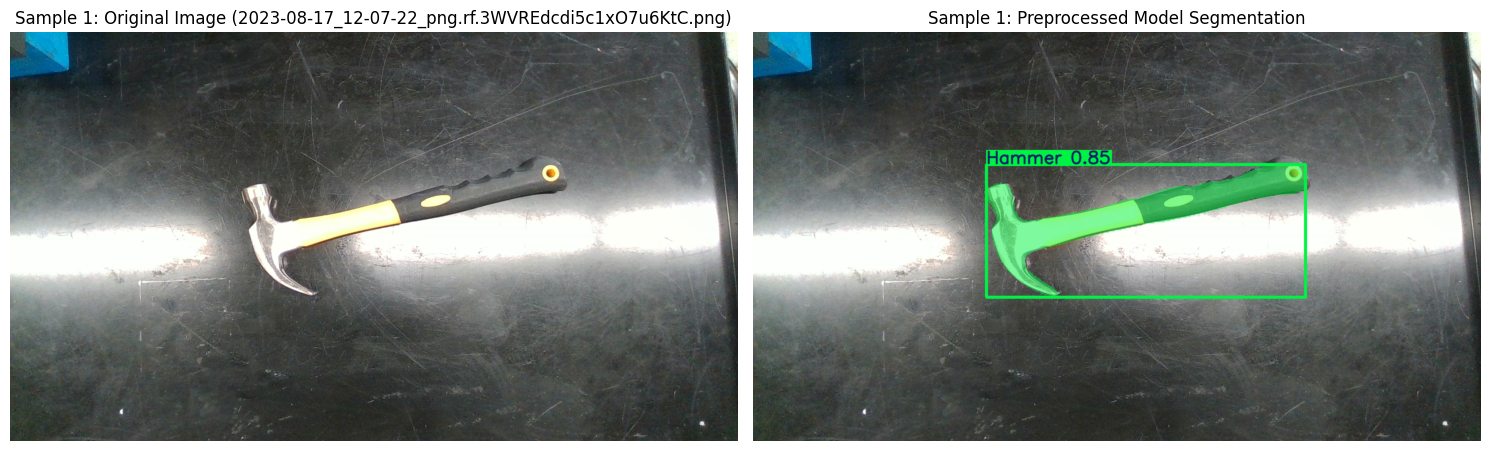


image 1/1 /content/yolo_dataset_modified/test/images/images173_jpg.rf.4duZs8QlJXnyzTYfAa2d.jpg: 448x640 1 Screwdriver, 71.5ms
Speed: 2.4ms preprocess, 71.5ms inference, 1.9ms postprocess per image at shape (1, 3, 448, 640)


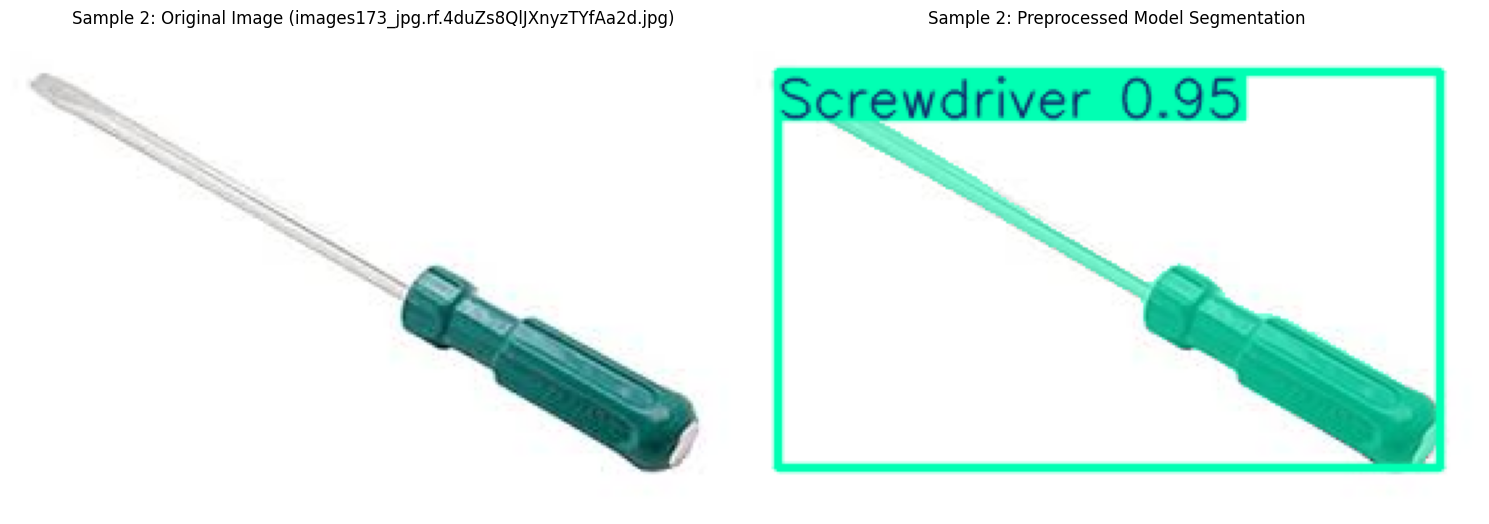


image 1/1 /content/yolo_dataset_modified/test/images/20231102150501_jpg.rf.4RQuuU4d5Zeg1bchjG0w.jpg: 384x640 3 Adjustable spanners, 3 Gas wrenchs, 2 Ratchets, 15.0ms
Speed: 1.5ms preprocess, 15.0ms inference, 3.1ms postprocess per image at shape (1, 3, 384, 640)


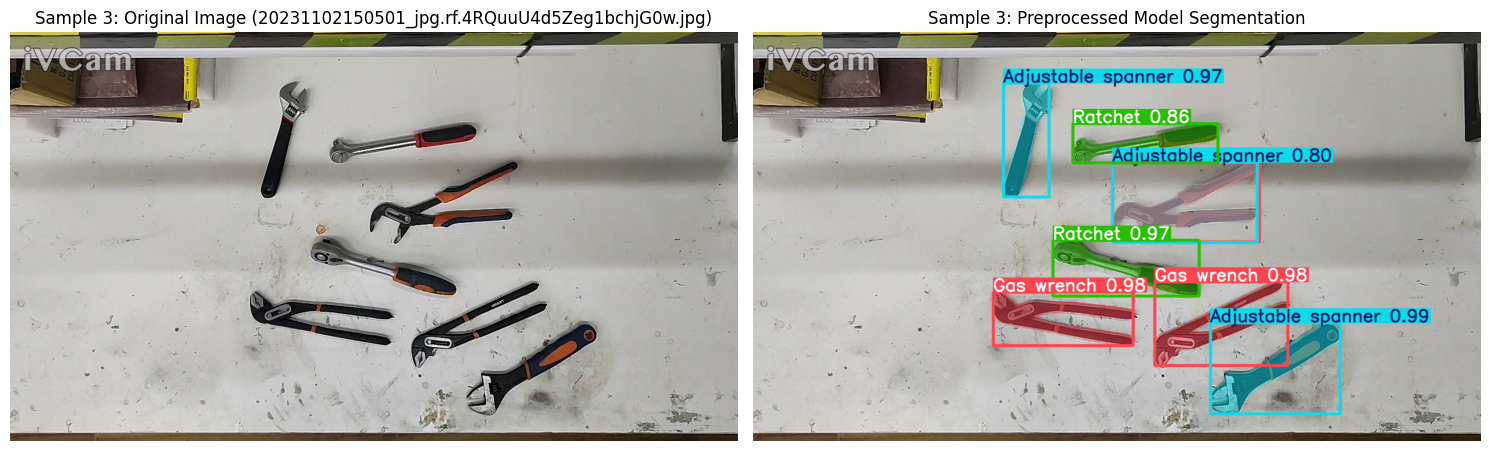


image 1/1 /content/yolo_dataset_modified/test/images/tool (282)_jpg.rf.0SoT5Yj5Srk0UHMkmnlG.jpg: 640x640 1 Screwdriver, 70.2ms
Speed: 3.6ms preprocess, 70.2ms inference, 3.4ms postprocess per image at shape (1, 3, 640, 640)


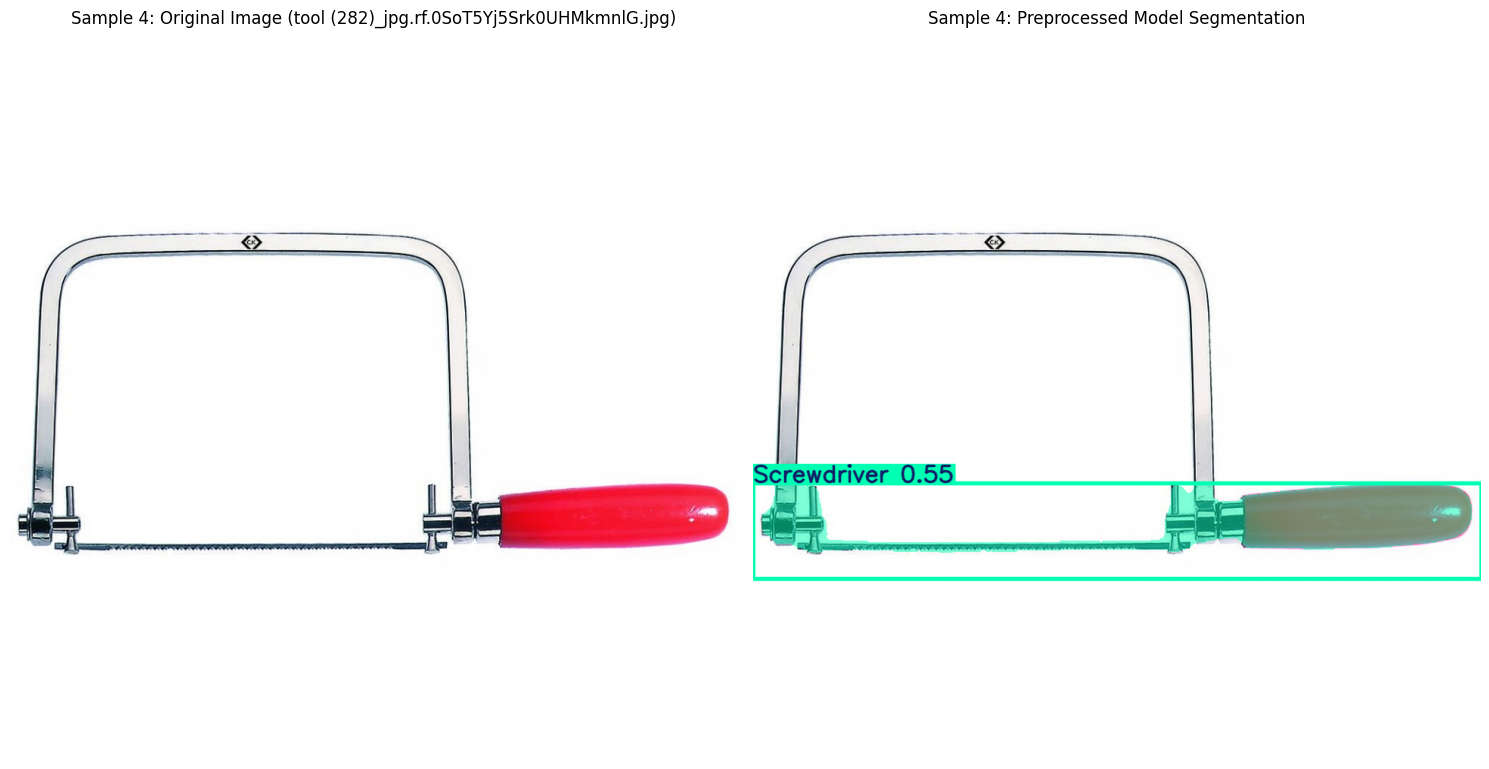


image 1/1 /content/yolo_dataset_modified/test/images/screw_driver839_jpg.rf.3RpNtzbD7Y67Zms2v3SV.jpg: 640x640 2 Screwdrivers, 16.7ms
Speed: 3.2ms preprocess, 16.7ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 640)


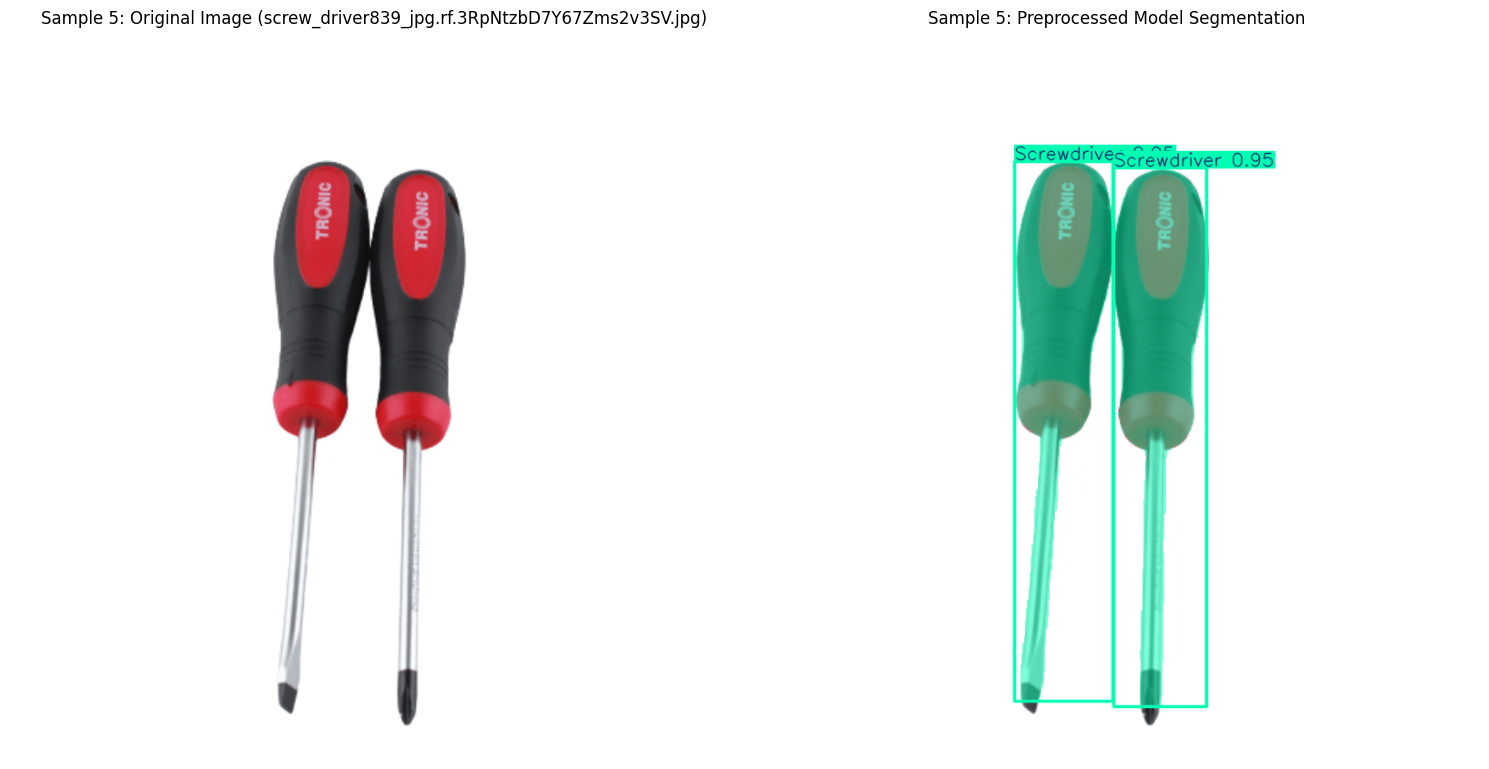

In [ ]:
import os
import sys
import glob
import random
import cv2
import matplotlib.pyplot as plt
from PIL import Image

try:
    from ultralytics import YOLO
except ImportError:
    print("Ultralytics package not found. Installing now...")
    !{sys.executable} -m pip install ultralytics
    from ultralytics import YOLO

# Load the best-performing model from our actual modified run directory
trained_mod_path = '/content/runs/segment/train-modified/weights/best.pt'

if os.path.exists(trained_mod_path):
    model_eval = YOLO(trained_mod_path)

    # Paths to local validation or test datasets
    test_images_dir = '/content/yolo_dataset_modified/test/images'
    test_images = glob.glob(os.path.join(test_images_dir, '*.*'))

    if test_images:
        # Select 5 random test images
        sampled_test_images = random.sample(test_images, min(5, len(test_images)))

        for idx, img_path in enumerate(sampled_test_images):
            # Load original image
            orig_img = Image.open(img_path)

            # Inference
            pred_results = model_eval(img_path, conf=0.25)

            # Plot the model predictions on the image (returns BGR format)
            result_bgr = pred_results[0].plot()
            result_rgb = cv2.cvtColor(result_bgr, cv2.COLOR_BGR2RGB)

            # Display original and predictions side-by-side
            fig, axes = plt.subplots(1, 2, figsize=(15, 8))

            axes[0].imshow(orig_img)
            axes[0].set_title(f"Sample {idx + 1}: Original Image ({os.path.basename(img_path)})")
            axes[0].axis('off')

            axes[1].imshow(result_rgb)
            axes[1].set_title(f"Sample {idx + 1}: Preprocessed Model Segmentation")
            axes[1].axis('off')

            plt.tight_layout()
            plt.show()
    else:
        print("No test images found to run predictions.")
else:
    print(f"Could not locate the trained model weights at {trained_mod_path}. Please make sure the training has finished successfully.")


image 1/1 /content/screwdriver.jpg: 352x640 3 Screwdrivers, 11.5ms
Speed: 1.7ms preprocess, 11.5ms inference, 1.9ms postprocess per image at shape (1, 3, 352, 640)


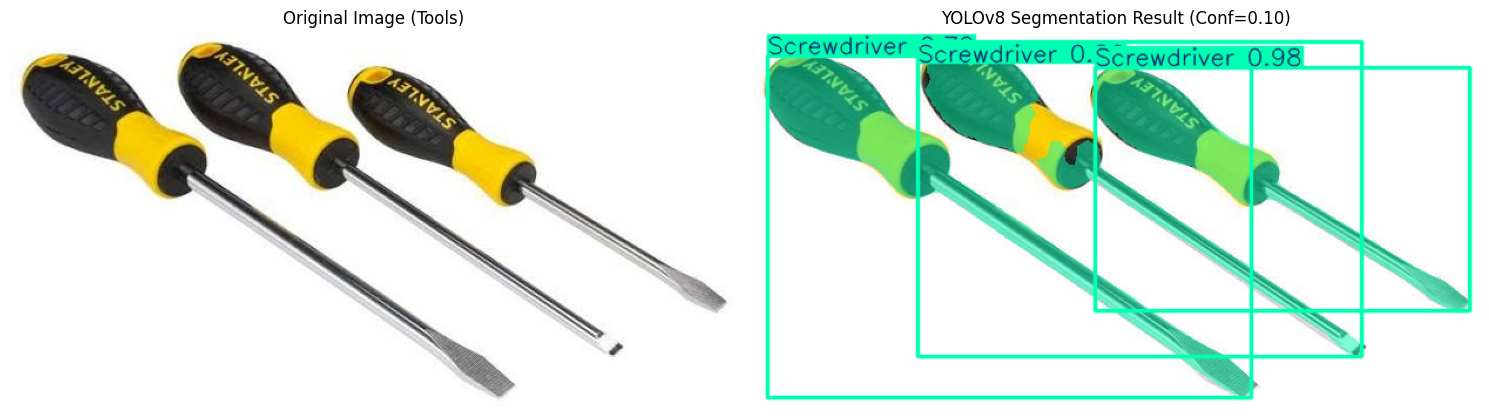

In [ ]:
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import os
from ultralytics import YOLO

test_image_path = '/content/screwdriver.jpg'
trained_model_path = '/content/runs/segment/train-modified/weights/best.pt'

if os.path.exists(test_image_path):
    if os.path.exists(trained_model_path):
        # 1. Load the original image
        orig_img = Image.open(test_image_path)

        # 2. Load the trained model and run inference with a lower confidence threshold
        model_modified_eval = YOLO(trained_model_path)
        pred_results = model_modified_eval(test_image_path, conf=0.10)

        # 3. Extract the plotted result image (convert BGR to RGB)
        result_bgr = pred_results[0].plot()
        result_rgb = cv2.cvtColor(result_bgr, cv2.COLOR_BGR2RGB)

        # 4. Plot side-by-side
        fig, axes = plt.subplots(1, 2, figsize=(15, 8))

        # Original Image
        axes[0].imshow(orig_img)
        axes[0].set_title("Original Image (Tools)")
        axes[0].axis('off')

        # Model Prediction
        axes[1].imshow(result_rgb)
        axes[1].set_title("YOLOv8 Segmentation Result (Conf=0.10)")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()
    else:
        print(f"Trained model weights not found at {trained_model_path}.")
else:
    print(f"The image was not found at {test_image_path}. Please make sure it is uploaded to that path.")

In [ ]:
import os
import shutil

# Define source and destination paths
runs_src = '/content/runs'
yaml_src = '/content/dataset_modified.yaml'

drive_dest_root = '/content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset'
target_drive_folder = os.path.join(drive_dest_root, 'evaluation_results_on_modified_dataset')

# 1. Create the target folder on Google Drive
os.makedirs(target_drive_folder, exist_ok=True)
print(f"Created directory: {target_drive_folder}")

# 2. Copy the training runs directory
if os.path.exists(runs_src):
    dest_runs_path = os.path.join(target_drive_folder, 'runs')
    if os.path.exists(dest_runs_path):
        shutil.rmtree(dest_runs_path)
    shutil.copytree(runs_src, dest_runs_path)
    print(f"Successfully copied training runs and weights to: {dest_runs_path}")
else:
    print(f"Runs directory not found at {runs_src}.")

# 3. Copy the modified dataset YAML configuration file
if os.path.exists(yaml_src):
    dest_yaml_path = os.path.join(target_drive_folder, 'dataset_modified.yaml')
    shutil.copy2(yaml_src, dest_yaml_path)
    print(f"Successfully saved dataset configuration to: {dest_yaml_path}")
else:
    print(f"{yaml_src} not found.")

Created directory: /content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset/evaluation_results_on_modified_dataset
Successfully copied training runs and weights to: /content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset/evaluation_results_on_modified_dataset/runs
Successfully saved dataset configuration to: /content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset/evaluation_results_on_modified_dataset/dataset_modified.yaml


# Load the model and test it

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

image 1/1 /content/tools.jpg: 640x608 2 Adjustable spanners, 18.4ms
Speed: 86.1ms preprocess, 18.4ms inference, 130.6ms postprocess per image at shape (1, 3, 640, 608)


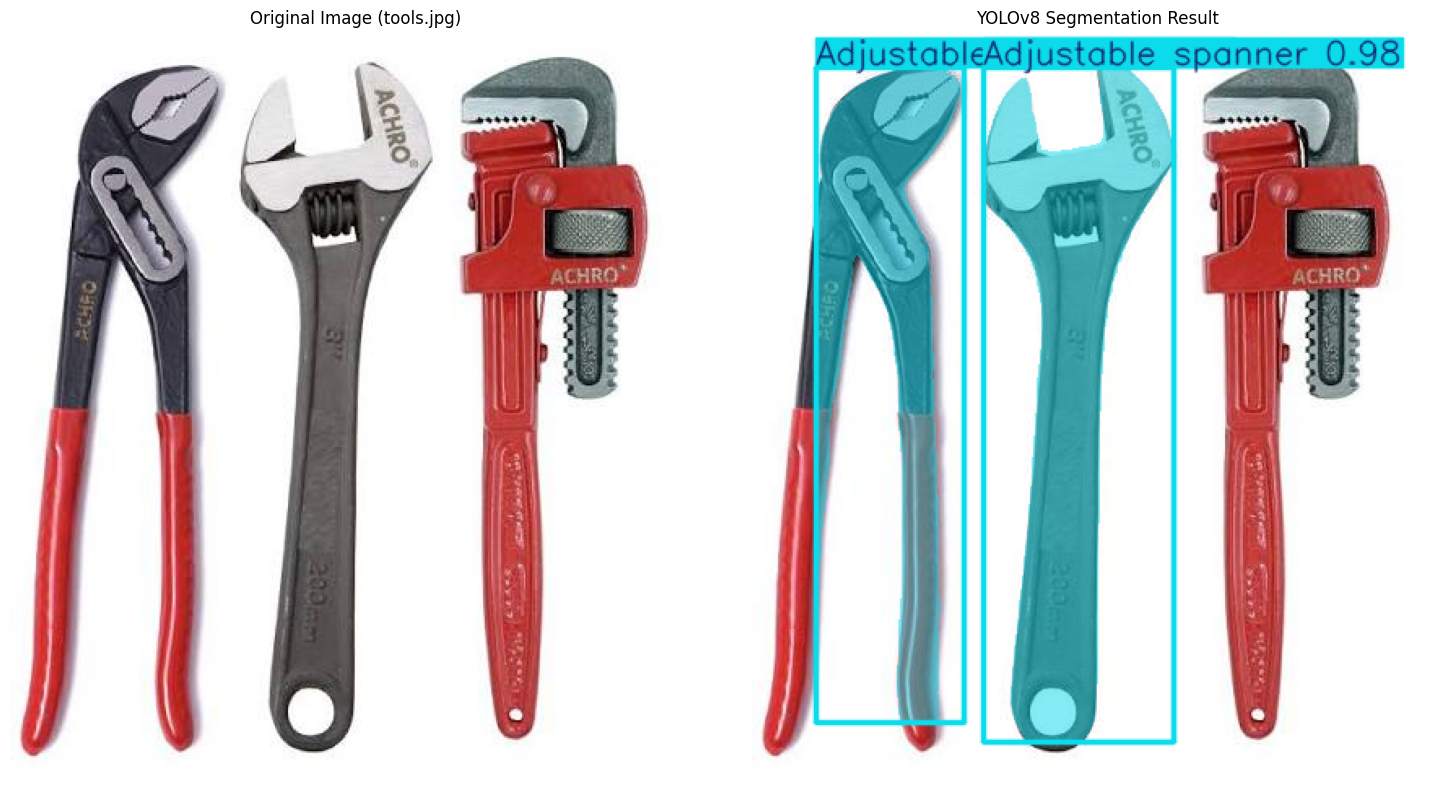

In [5]:
import os
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

# Define paths
model_path = '/content/drive/MyDrive/CV Project/Dataset/Roboflow Dataset/evaluation_results_on_modified_dataset/runs/segment/train-modified/weights/best.pt'
test_image_path = '/content/tools.jpg'

# Check if both model and image exist
if not os.path.exists(model_path):
    print(f"Error: Model not found at {model_path}")
elif not os.path.exists(test_image_path):
    print(f"Error: Image not found at {test_image_path}")
else:
    # 1. Load the original image
    orig_img = Image.open(test_image_path)

    # 2. Load the trained model
    model = YOLO(model_path)

    # 3. Run inference
    pred_results = model(test_image_path, conf=0.25)

    # 4. Extract and convert result image (BGR to RGB)
    result_bgr = pred_results[0].plot()
    result_rgb = cv2.cvtColor(result_bgr, cv2.COLOR_BGR2RGB)

    # 5. Plot side-by-side comparison
    fig, axes = plt.subplots(1, 2, figsize=(15, 8))

    # Original Image
    axes[0].imshow(orig_img)
    axes[0].set_title("Original Image (tools.jpg)")
    axes[0].axis('off')

    # Model Prediction
    axes[1].imshow(result_rgb)
    axes[1].set_title("YOLOv8 Segmentation Result")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()